## 1. INTRODUCTION

E-commerce has become an important part of modern business. This project focuses on analyzing e-commerce sales data and customer purchasing behavior using Python.

The main objective is to understand sales performance, customer preferences, product performance, payment methods, marketing channels, and business trends through data analysis and visualization.

**Dataset Source:** Kaggle – E-Commerce Sales Analytics Dataset

**Dataset Link:** https://www.kaggle.com/code/sometimessubodh/the-e-commerce-story-decoding-138k-orders/input

**Dataset Details:**
- Main Dataset: ecommerce_sales_customer_analytics_150k.csv
- Total Records: 138,116
- Total Columns: 46
- Data Period: 2021–2025
- Data Format: CSV

**Tools and Libraries Used:** Python, Pandas, NumPy, Matplotlib, and Seaborn.

# 2. Project Objectives

The main objectives of this project are:

1. To understand and analyze the e-commerce dataset.
2. To clean the data by handling missing values and duplicate records.
3. To analyze sales performance and customer purchasing behavior.
4. To identify top-performing products and product categories.
5. To analyze revenue and profitability trends.
6. To perform statistical analysis and identify relationships between variables.
7. To create meaningful visualizations using Matplotlib and Seaborn.
8. To generate business insights and provide recommendations for improving business performance.

# E-Commerce Sales & Customer Behavior Analysis

## Project Objective
To analyze e-commerce sales, customer behavior,
product performance, and profitability using Python.

## Tools Used
Python, Pandas, NumPy, Matplotlib, Seaborn.

# 3. Data Loading and Initial Data Overview

In this section, we load the e-commerce dataset using Pandas and examine its structure, dimensions, data types, and statistical summaries to understand the data before preprocessing.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

from google.colab import files

uploaded = files.upload()

zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('/content/ecommerce_data')

df = pd.read_csv(
    '/content/ecommerce_data/ecommerce_sales_customer_analytics_150k.csv'
)

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)
display(df.head())

Saving archive (5).zip to archive (5).zip
Dataset Loaded Successfully!
Shape: (138116, 46)


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


# 4. Data Quality Check

In this section, we examine missing values, duplicate records, and data types to identify data quality issues before cleaning.

In [ ]:
print("Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Records:", df.duplicated().sum())

Data Types:
order_id                     object
order_date                   object
order_time                   object
order_status                 object
sales_channel                object
customer_id                  object
customer_name                object
customer_age                  int64
gender                       object
customer_segment             object
customer_type                object
customer_city                object
customer_state               object
customer_country             object
region                       object
customer_postal_code          int64
payment_method               object
payment_status               object
currency                     object
shipping_method              object
warehouse                    object
delivery_days               float64
estimated_delivery_days     float64
delivery_status              object
return_status                object
return_reason                object
customer_rating             float64
review_sentiment

# 5. Data Cleaning and Preprocessing

In this section, missing values and data types are handled carefully to improve data quality and prepare the dataset for further analysis.

In [ ]:
# Convert date and time columns

df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
df['order_time'] = pd.to_datetime(
    df['order_time'], format='%H:%M:%S', errors='coerce'
).dt.time

# Verify changes
print(df[['order_date', 'order_time']].dtypes)

order_date    datetime64[ns]
order_time            object
dtype: object


# 6. Feature Engineering

In this section, new date-based features are created from the order date to analyze yearly, monthly, and daily sales trends.

In [ ]:
df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month
df['order_day'] = df['order_date'].dt.day

print("New Columns Created Successfully!")
display(df[['order_date', 'order_year', 'order_month', 'order_day']].head())

New Columns Created Successfully!


,order_date,order_year,order_month,order_day
0,2023-11-06,2023,11,6
1,2025-12-24,2025,12,24
2,2021-07-05,2021,7,5
3,2023-01-21,2023,1,21
4,2022-05-13,2022,5,13


# 7. Handling Missing Values

In this section, missing values are handled based on the nature and purpose of each column. Optional business information is preserved appropriately, while numerical and review-related missing values are handled carefully.

In [ ]:
# Handle optional categorical information

df['return_status'] = df['return_status'].fillna('Not Returned')
df['return_reason'] = df['return_reason'].fillna('Not Applicable')
df['campaign_name'] = df['campaign_name'].fillna('No Campaign')
df['coupon_code'] = df['coupon_code'].fillna('No Coupon')

# Check remaining missing values
print(df.isnull().sum()[df.isnull().sum() > 0])

delivery_days              24557
estimated_delivery_days    24557
customer_rating            24557
review_sentiment           24557
customer_review            24557
dtype: int64


# 8. Handling Remaining Missing Values

Missing values in delivery and customer feedback columns are handled carefully. Median imputation is used for numerical columns, while categorical and text columns are labelled as unavailable where appropriate.# 8. Handling Remaining Missing Values

Missing values in delivery and customer feedback columns are handled carefully. Median imputation is used for numerical columns, while categorical and text columns are labelled as unavailable where appropriate.

In [ ]:
# Numerical columns: fill with median
df['delivery_days'] = df['delivery_days'].fillna(df['delivery_days'].median())

df['estimated_delivery_days'] = df['estimated_delivery_days'].fillna(
    df['estimated_delivery_days'].median()
)

df['customer_rating'] = df['customer_rating'].fillna(
    df['customer_rating'].median()
)

# Categorical and text columns
df['review_sentiment'] = df['review_sentiment'].fillna('No Review')
df['customer_review'] = df['customer_review'].fillna('No Review')

# Final missing value check
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


# 9. Final Data Cleaning Verification

In this section, the cleaned dataset is verified to ensure that missing values and duplicate records have been handled successfully.

In [ ]:
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicate Records:", df.duplicated().sum())

print("\nFinal Dataset:")
display(df.head())

Dataset Shape: (138116, 49)
Total Missing Values: 0
Total Duplicate Records: 0

Final Dataset:


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count,order_year,order_month,order_day
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,945.40,588.33,345.04,36.50,12459.68,True,11,2023,11,6
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,2018.41,2031.88,-22.47,-1.11,13032.48,True,11,2025,12,24
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,468.35,257.73,197.57,42.18,6159.44,True,6,2021,7,5
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,546.52,277.84,247.83,45.35,5638.30,True,7,2023,1,21
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,2785.27,1231.88,1530.36,54.94,13240.10,True,8,2022,5,13


# 10. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand sales performance, customer behavior, and business trends using statistical summaries and data analysis techniques.

In [ ]:
# Descriptive Statistical Analysis

display(df.describe().T)

print("Total Revenue:", round(df['net_sales'].sum(), 2))
print("Total Profit:", round(df['profit'].sum(), 2))
print("Average Sales:", round(df['net_sales'].mean(), 2))
print("Total Orders:", df['order_id'].nunique())

,count,mean,min,25%,50%,75%,max,std
order_date,138116,2023-07-21 10:11:31.662081280,2021-01-01 00:00:00,2022-04-20 00:00:00,2023-08-01 00:00:00,2024-10-29 00:00:00,2025-12-31 00:00:00,NaN
customer_age,138116.0,45.862681,18.0,32.0,46.0,60.0,74.0,16.467676
customer_postal_code,138116.0,50210.88931,516.0,25509.0,50183.0,74898.0,99950.0,28569.767779
delivery_days,138116.0,4.4586,0.0,3.0,4.0,6.0,14.0,2.556892
estimated_delivery_days,138116.0,4.245735,0.0,3.0,4.0,6.0,10.0,2.354961
customer_rating,138116.0,3.681101,1.6,3.4,3.7,3.9,5.0,0.438658
loyalty_points_earned,138116.0,103.991051,0.0,17.0,70.0,151.0,1621.0,115.17564
loyalty_points_redeemed,138116.0,51.934128,0.0,3.0,25.0,71.0,1063.0,73.217692
quantity,138116.0,5.615244,1.0,3.0,5.0,8.0,24.0,3.371289
gross_sales,138116.0,1375.384176,6.31,458.92,995.73,1871.2,16051.19,1291.009554


Total Revenue: 177134263.74
Total Profit: 76146395.76
Average Sales: 1282.5
Total Orders: 138116


# 11. Sales Performance Analysis

In this section, sales performance is analyzed based on yearly and monthly revenue to identify business growth patterns and sales trends.

In [ ]:
yearly_analysis = df.groupby('order_year').agg(
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum'),
    Total_Orders=('order_id', 'nunique')
).reset_index()

display(yearly_analysis)

,order_year,Total_Revenue,Total_Profit,Total_Orders
0,2021,35722650.67,15325651.87,27554
1,2022,35327882.62,15167978.69,27564
2,2023,35528143.74,15247695.95,27632
3,2024,35466452.28,15292965.09,27768
4,2025,35089134.43,15112104.16,27598


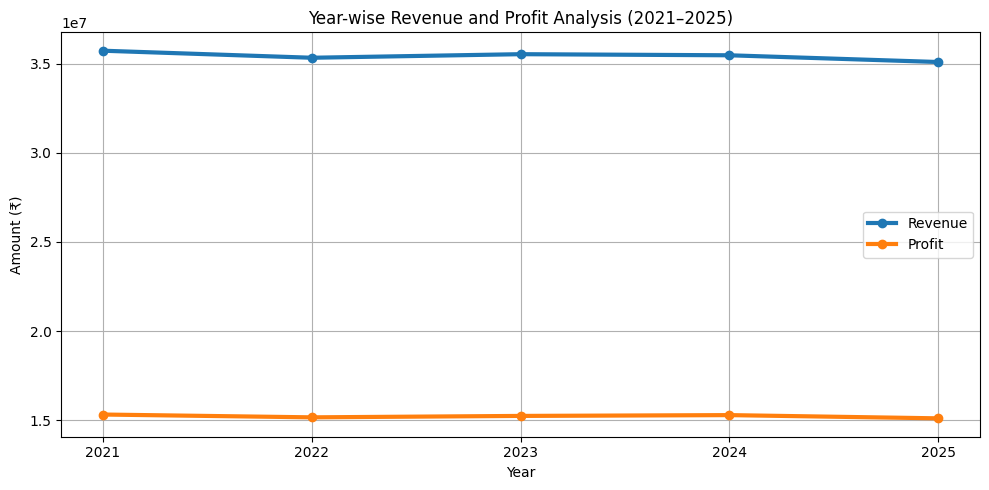

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(yearly_analysis['order_year'],
         yearly_analysis['Total_Revenue'],
         marker='o', linewidth=3, label='Revenue')

plt.plot(yearly_analysis['order_year'],
         yearly_analysis['Total_Profit'],
         marker='o', linewidth=3, label='Profit')

plt.title('Year-wise Revenue and Profit Analysis (2021–2025)')
plt.xlabel('Year')
plt.ylabel('Amount (₹)')
plt.xticks(yearly_analysis['order_year'])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

KEY INSIGHTS – YEAR-WISE SALES & PROFIT ANALYSIS

1. The highest revenue was recorded in 2021, with ₹3.57 Crores.

2. The lowest revenue was recorded in 2025, with ₹3.51 Crores.

3. The highest profit was recorded in 2021, at ₹1.53 Crores.

4. The lowest profit was recorded in 2025, at ₹1.51 Crores.

5. The highest number of orders was recorded in 2024, with 27,768 orders.

6. Revenue and profit remained relatively stable throughout the five-year period, with only minor fluctuations.

# 12. Monthly Sales Analysis

This analysis examines monthly revenue to identify high-performing and low-performing months.

In [ ]:
monthly_sales = df.groupby('order_month')['net_sales'].sum().reset_index()

monthly_sales.columns = ['Month', 'Total_Revenue']

display(monthly_sales)

,Month,Total_Revenue
0,1,12238598.83
1,2,10108027.56
2,3,13679516.86
3,4,12654092.89
4,5,12626730.13
5,6,13470903.94
6,7,14054324.07
7,8,15058347.23
8,9,13814730.98
9,10,14606076.52


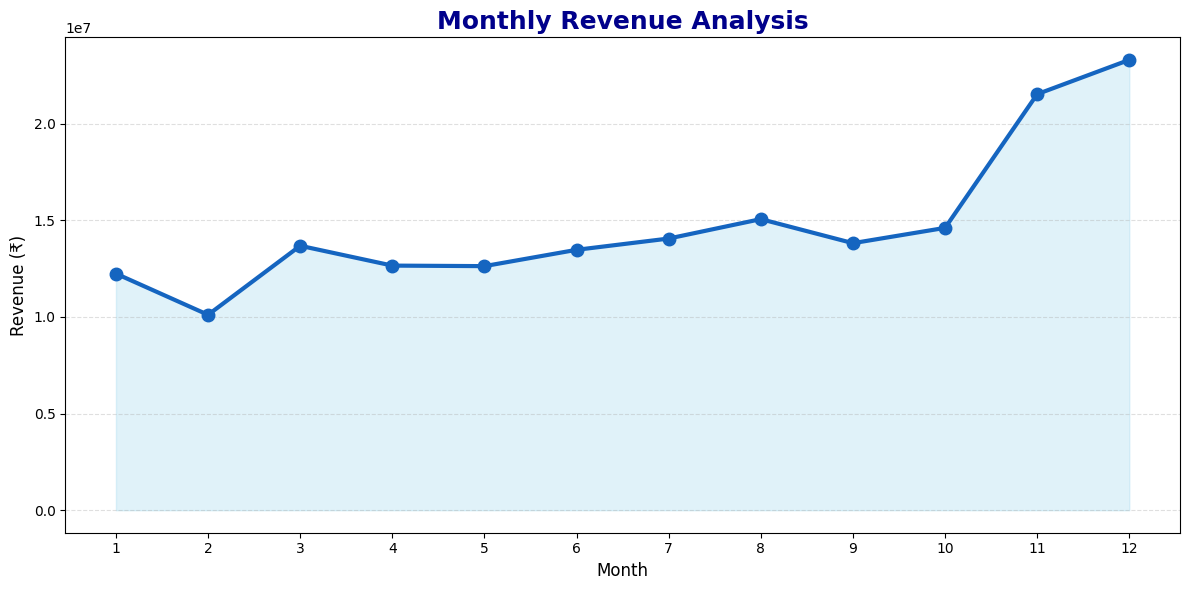

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(monthly_sales['Month'],
         monthly_sales['Total_Revenue'],
         marker='o',
         color='#1565C0',
         linewidth=3,
         markersize=9)

plt.fill_between(monthly_sales['Month'],
                 monthly_sales['Total_Revenue'],
                 color='skyblue',
                 alpha=0.25)

plt.title('Monthly Revenue Analysis',
          fontsize=18, fontweight='bold', color='darkblue')

plt.xlabel('Month', fontsize=12)
plt.ylabel('Revenue (₹)', fontsize=12)

plt.xticks(range(1,13))
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
# Find category-related columns
[col for col in df.columns if 'category' in col.lower()]

[]

In [ ]:
df.columns.tolist()

['order_id',
 'order_date',
 'order_time',
 'order_status',
 'sales_channel',
 'customer_id',
 'customer_name',
 'customer_age',
 'gender',
 'customer_segment',
 'customer_type',
 'customer_city',
 'customer_state',
 'customer_country',
 'region',
 'customer_postal_code',
 'payment_method',
 'payment_status',
 'currency',
 'shipping_method',
 'warehouse',
 'delivery_days',
 'estimated_delivery_days',
 'delivery_status',
 'return_status',
 'return_reason',
 'customer_rating',
 'review_sentiment',
 'customer_review',
 'marketing_channel',
 'campaign_name',
 'coupon_code',
 'loyalty_points_earned',
 'loyalty_points_redeemed',
 'quantity',
 'gross_sales',
 'discount_amount',
 'tax_amount',
 'shipping_cost',
 'net_sales',
 'product_cost',
 'profit',
 'profit_margin_percentage',
 'customer_lifetime_value',
 'is_repeat_customer',
 'customer_order_count',
 'order_year',
 'order_month',
 'order_day']

### Key Insights
1. December recorded the highest revenue of ₹2.33 Crores.
2. November recorded the second-highest revenue of ₹2.15 Crores.
3. February recorded the lowest revenue of ₹1.01 Crores.
4. Sales increased significantly during the last two months of the year.
5. Seasonal demand appears to contribute to higher year-end sales.

# 13. Sales Channel Analysis

This analysis compares revenue generated through different sales channels to identify the best-performing channel.

In [ ]:
channel_sales = df.groupby('sales_channel').agg(
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum'),
    Total_Orders=('order_id', 'nunique')
).reset_index()

display(channel_sales)

,sales_channel,Total_Revenue,Total_Profit,Total_Orders
0,Marketplace,26696190.22,11414227.16,20698
1,Mobile App,70834782.53,30451112.22,55318
2,Social Media,17748554.91,7641363.37,13863
3,Website,61854736.08,26639693.01,48237


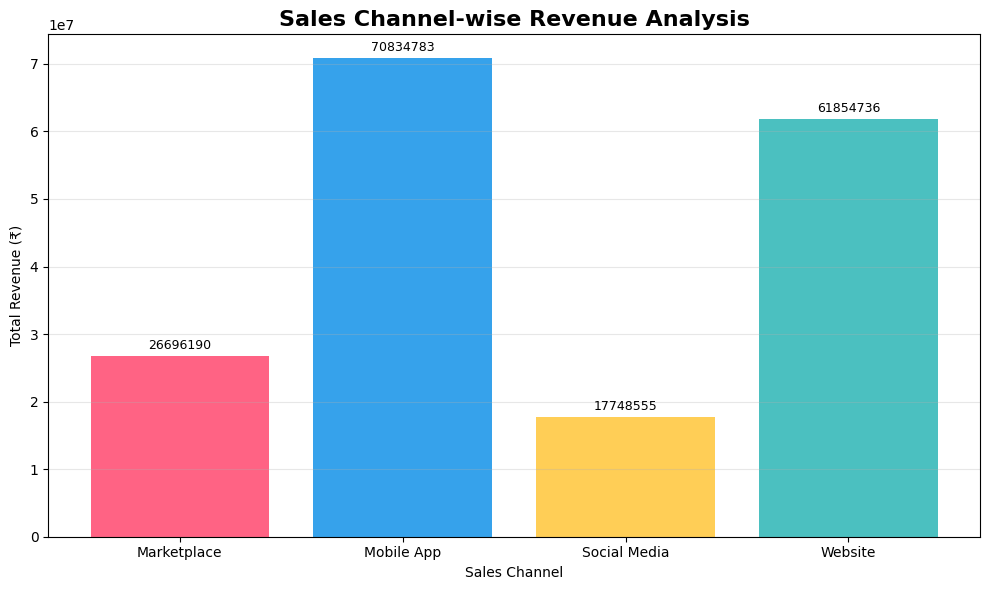

In [ ]:
plt.figure(figsize=(10,6))

bars = plt.bar(
    channel_sales['sales_channel'],
    channel_sales['Total_Revenue'],
    color=['#FF6384', '#36A2EB', '#FFCE56', '#4BC0C0']
)

plt.title('Sales Channel-wise Revenue Analysis',
          fontsize=16, fontweight='bold')

plt.xlabel('Sales Channel')
plt.ylabel('Total Revenue (₹)')

plt.bar_label(bars, fmt='%.0f', padding=3, fontsize=9)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Key Insights
1. Mobile App generated the highest revenue of ₹7.08 Crores.
2. Website generated ₹6.19 Crores in revenue.
3. Marketplace generated ₹2.67 Crores.
4. Social Media generated ₹1.77 Crores.
5. Mobile App recorded the highest order count with 55,318 orders.
6. Mobile App and Website are the major sales channels.

# 14. Payment Method Analysis

This analysis identifies the most popular payment methods and compares revenue generated through each payment method.

In [ ]:
payment_analysis = df.groupby('payment_method').agg(
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum'),
    Total_Orders=('order_id', 'nunique')
).reset_index()

display(payment_analysis)

,payment_method,Total_Revenue,Total_Profit,Total_Orders
0,Bank Transfer,8923932.79,3841483.71,6965
1,Buy Now Pay Later,13974727.03,6013888.29,11061
2,Cash on Delivery,18025912.13,7760710.32,13863
3,Credit Card,53389617.40,22938460.01,41460
4,Debit Card,35355144.13,15175704.84,27635
5,Digital Wallet,20832787.20,8981744.41,16382
6,PayPal,26632143.06,11434404.18,20750


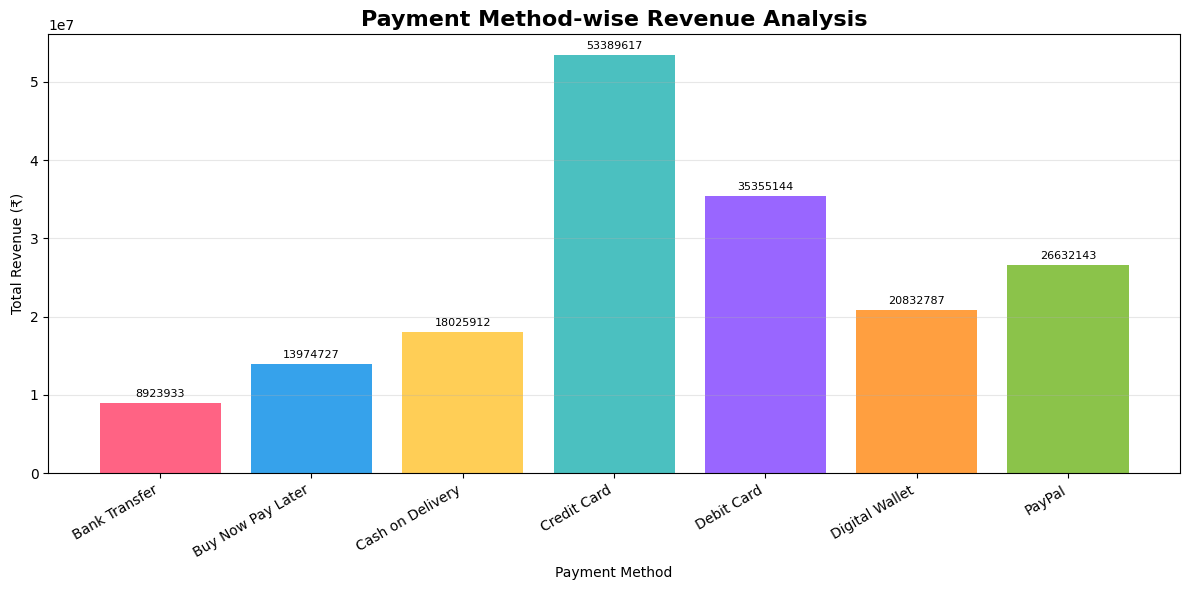

In [ ]:
plt.figure(figsize=(12,6))

bars = plt.bar(
    payment_analysis['payment_method'],
    payment_analysis['Total_Revenue'],
    color=['#FF6384', '#36A2EB', '#FFCE56',
           '#4BC0C0', '#9966FF', '#FF9F40', '#8BC34A']
)

plt.title('Payment Method-wise Revenue Analysis',
          fontsize=16, fontweight='bold')

plt.xlabel('Payment Method')
plt.ylabel('Total Revenue (₹)')

plt.xticks(rotation=30, ha='right')
plt.bar_label(bars, fmt='%.0f', padding=3, fontsize=8)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Key Insights
1. Credit Card generated the highest revenue of ₹5.34 Crores.
2. Debit Card generated ₹3.54 Crores.
3. PayPal generated ₹2.66 Crores.
4. Bank Transfer recorded the lowest revenue of ₹89.24 Lakhs.
5. Credit Card recorded the highest order count with 41,460 orders.
6. Digital payment methods contribute significantly to sales.

# 15. Customer Segment Analysis

This analysis compares revenue, profit, and order count across different customer segments to identify the most valuable customer groups.

In [ ]:
segment_analysis = df.groupby('customer_segment').agg(
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum'),
    Total_Orders=('order_id', 'nunique')
).reset_index()

display(segment_analysis)

,customer_segment,Total_Revenue,Total_Profit,Total_Orders
0,Business,17760296.90,7782525.28,13777
1,Consumer,97201007.90,42819790.02,75636
2,Premium,44269794.13,18177727.78,34746
3,VIP,17903164.81,7366352.68,13957


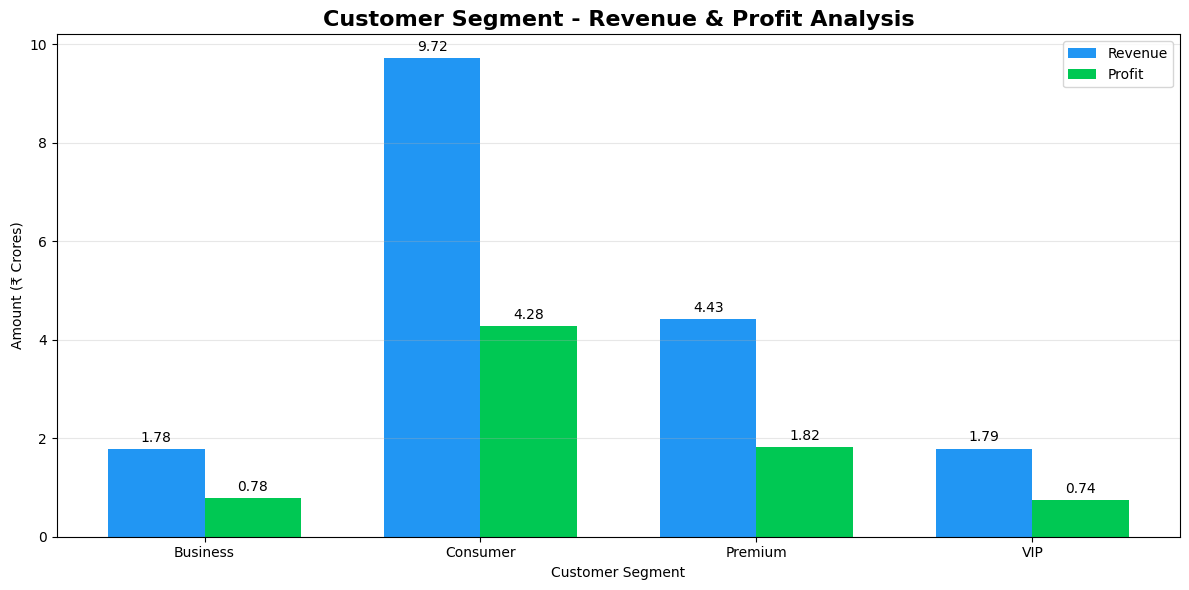

In [ ]:
x = np.arange(len(segment_analysis))
width = 0.35

plt.figure(figsize=(12,6))

bars1 = plt.bar(
    x - width/2,
    segment_analysis['Total_Revenue']/10000000,
    width,
    label='Revenue',
    color='#2196F3'
)

bars2 = plt.bar(
    x + width/2,
    segment_analysis['Total_Profit']/10000000,
    width,
    label='Profit',
    color='#00C853'
)

plt.title('Customer Segment - Revenue & Profit Analysis',
          fontsize=16, fontweight='bold')

plt.xlabel('Customer Segment')
plt.ylabel('Amount (₹ Crores)')

plt.xticks(x, segment_analysis['customer_segment'])
plt.bar_label(bars1, fmt='%.2f', padding=3)
plt.bar_label(bars2, fmt='%.2f', padding=3)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Key Insights
1. Consumer segment generated the highest revenue of ₹9.72 Crores.
2. Premium customers generated ₹4.43 Crores.
3. VIP customers generated ₹1.79 Crores.
4. Business customers generated ₹1.78 Crores.
5. Consumer segment recorded the highest order count of 75,636.
6. Consumer customers are the major revenue contributors.

# 16. Region-wise Sales Analysis

This analysis compares revenue and profit across different regions to identify the best-performing geographical areas.

In [ ]:
region_analysis = df.groupby('region').agg(
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum'),
    Total_Orders=('order_id', 'nunique')
).reset_index()

display(region_analysis)

,region,Total_Revenue,Total_Profit,Total_Orders
0,Central,37171107.17,15572868.84,29627
1,East,27054887.88,11179366.94,21602
2,North,22565177.24,10402961.34,16624
3,South,55587994.98,23343946.17,43990
4,West,34755096.47,15647252.47,26273


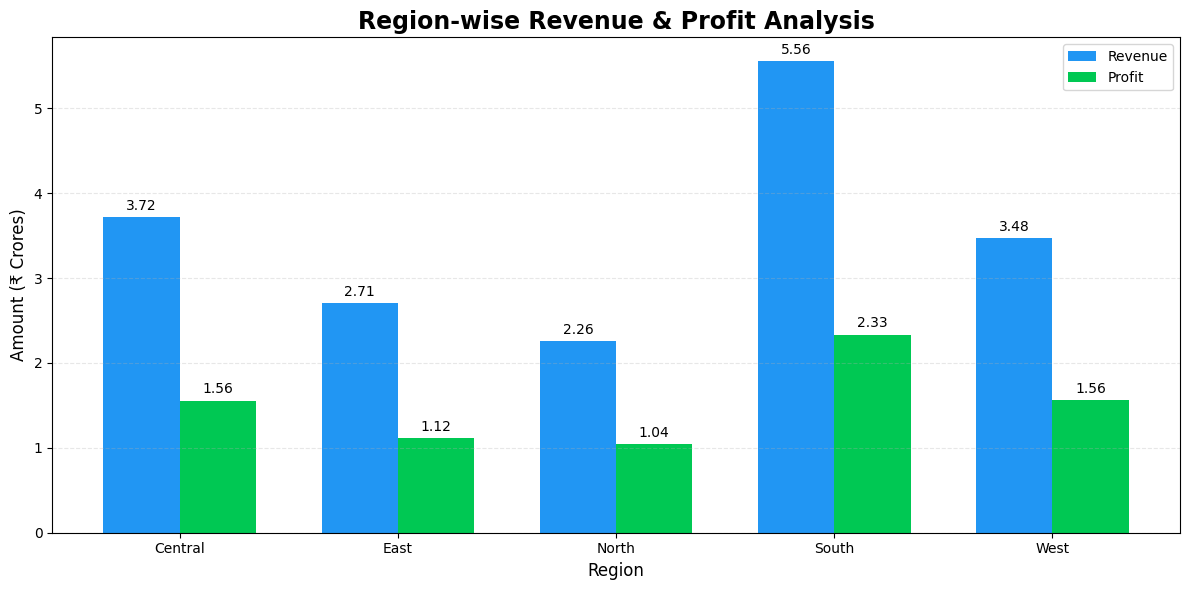

In [ ]:
plt.figure(figsize=(12,6))

x = np.arange(len(region_analysis))
width = 0.35

bars1 = plt.bar(
    x - width/2,
    region_analysis['Total_Revenue']/10000000,
    width,
    label='Revenue',
    color='#2196F3'
)

bars2 = plt.bar(
    x + width/2,
    region_analysis['Total_Profit']/10000000,
    width,
    label='Profit',
    color='#00C853'
)

plt.title('Region-wise Revenue & Profit Analysis',
          fontsize=17, fontweight='bold')

plt.xlabel('Region', fontsize=12)
plt.ylabel('Amount (₹ Crores)', fontsize=12)

plt.xticks(x, region_analysis['region'])

plt.bar_label(bars1, fmt='%.2f', padding=3)
plt.bar_label(bars2, fmt='%.2f', padding=3)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

### Key Insights

- South region generates the highest revenue of ₹5.56 Crores.
- South region records the highest profit of ₹2.33 Crores.
- South region has the highest number of orders (43,990).
- North region has the lowest revenue among all regions.
- Business performance is strongest in the South region.

# 17. Customer Age Analysis

This analysis studies customer age groups to understand purchasing behavior and identify the most valuable age group.

In [ ]:
df['Age_Group'] = pd.cut(
    df['customer_age'],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=['Below 20', '21-30', '31-40', '41-50', '51-60', 'Above 60']
)

age_analysis = df.groupby('Age_Group', observed=False).agg(
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum'),
    Total_Orders=('order_id', 'nunique')
).reset_index()

display(age_analysis)

,Age_Group,Total_Revenue,Total_Profit,Total_Orders
0,Below 20,9412764.49,4072812.54,7391
1,21-30,31351405.14,13470781.52,24462
2,31-40,31731454.39,13603145.16,24634
3,41-50,31039233.98,13308900.27,24244
4,51-60,30589973.37,13158150.83,23839
5,Above 60,43009432.37,18532605.44,33546


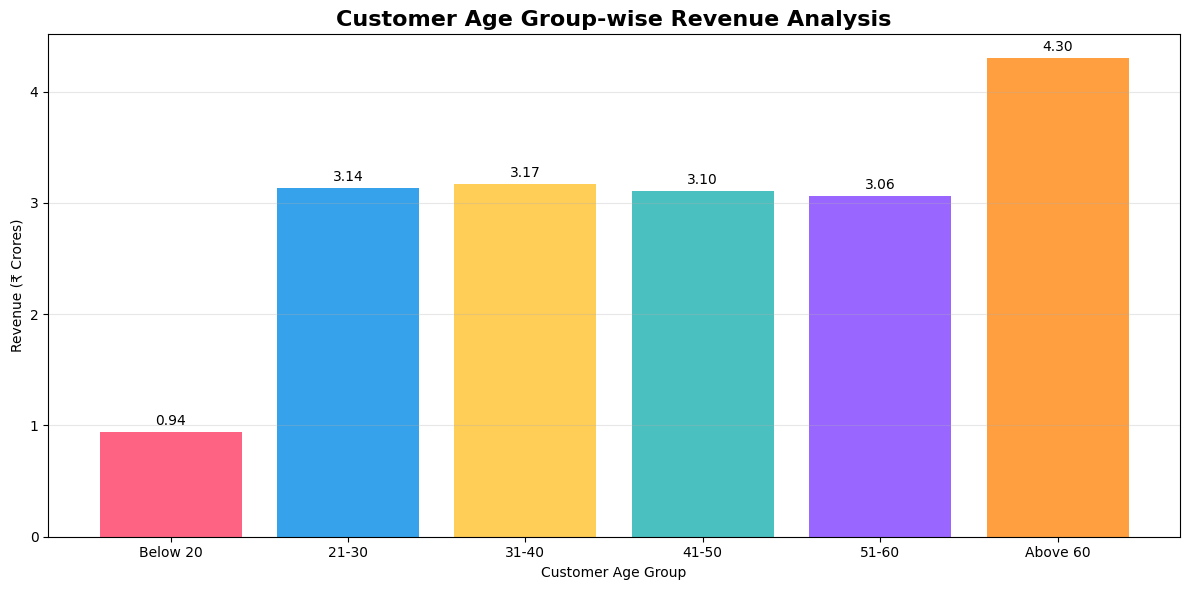

In [ ]:
plt.figure(figsize=(12,6))

bars = plt.bar(
    age_analysis['Age_Group'].astype(str),
    age_analysis['Total_Revenue']/10000000,
    color=['#FF6384', '#36A2EB', '#FFCE56',
           '#4BC0C0', '#9966FF', '#FF9F40']
)

plt.title('Customer Age Group-wise Revenue Analysis',
          fontsize=16, fontweight='bold')

plt.xlabel('Customer Age Group')
plt.ylabel('Revenue (₹ Crores)')

plt.bar_label(bars, fmt='%.2f', padding=3)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Key Insights

1. Customers above 60 years generate the highest revenue of ₹4.30 Crores.

2. The above 60 age group also generates the highest profit of ₹1.85 Crores.

3. Customers aged 31–40 generate ₹3.17 Crores in revenue, making them the second-highest revenue group.

4. Customers below 20 years generate the lowest revenue of ₹94.13 Lakhs.

5. The above 60 age group has the highest number of orders (33,546).

6. Customers aged 21–60 show relatively consistent revenue performance.

### Business Recommendation

Focus on customers above 60 with targeted offers and loyalty programs. Also develop marketing campaigns for customers aged 21–40 to increase sales.

# 18. Gender-wise Sales Analysis

This analysis compares revenue, profit, and order count across different customer genders to understand purchasing patterns.

In [ ]:
gender_analysis = df.groupby('gender').agg(
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum'),
    Total_Orders=('order_id', 'nunique')
).reset_index()

display(gender_analysis)

,gender,Total_Revenue,Total_Profit,Total_Orders
0,Female,85215914.19,36600361.14,66439
1,Male,84900594.89,36503017.19,66284
2,Non-Binary,7017754.66,3043017.43,5393


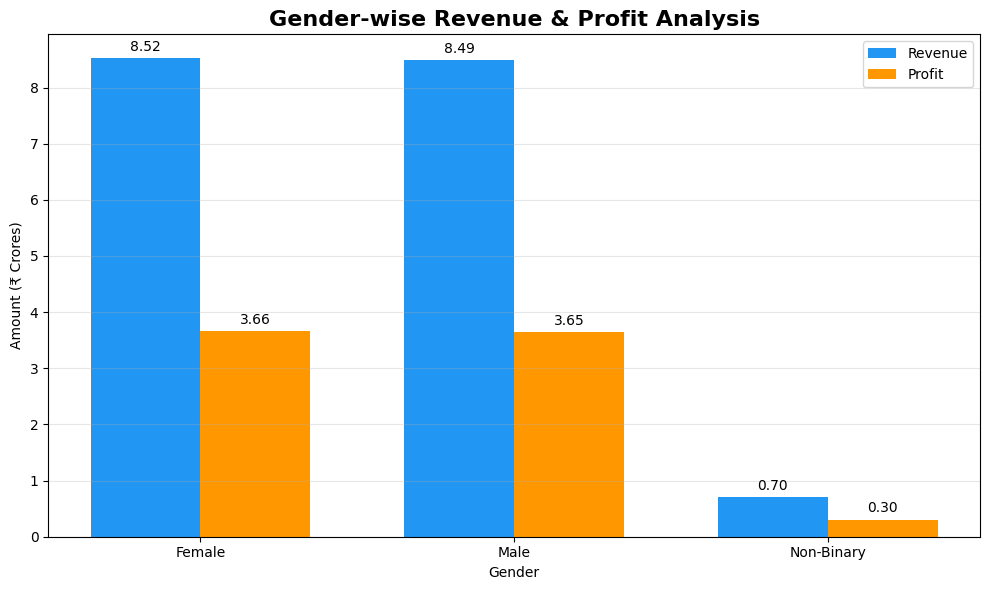

In [ ]:
plt.figure(figsize=(10,6))

x = np.arange(len(gender_analysis))
width = 0.35

bars1 = plt.bar(
    x - width/2,
    gender_analysis['Total_Revenue']/10000000,
    width,
    label='Revenue',
    color='#2196F3'
)

bars2 = plt.bar(
    x + width/2,
    gender_analysis['Total_Profit']/10000000,
    width,
    label='Profit',
    color='#FF9800'
)

plt.title('Gender-wise Revenue & Profit Analysis',
          fontsize=16, fontweight='bold')

plt.xlabel('Gender')
plt.ylabel('Amount (₹ Crores)')

plt.xticks(x, gender_analysis['gender'])

plt.bar_label(bars1, fmt='%.2f', padding=3)
plt.bar_label(bars2, fmt='%.2f', padding=3)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Key Insights

1. Revenue performance varies across different gender groups.
2. Profit contribution differs between customer gender groups.
3. The gender group with the highest revenue represents the strongest sales contribution.
4. Order counts help identify customer purchasing participation.
5. Gender-based purchasing patterns can support better marketing decisions.

### Business Recommendations

1. Develop targeted marketing campaigns based on customer purchasing patterns.
2. Provide personalized offers to improve customer engagement.
3. Analyze customer preferences before launching promotional campaigns.
4. Focus on customer retention through loyalty programs.
5. Monitor revenue and profit trends across gender groups regularly.

# 19. Order Status Analysis

This analysis examines different order statuses to understand order completion, cancellation, and pending order patterns.

In [ ]:
order_status_analysis = df.groupby('order_status').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(order_status_analysis)

,order_status,Total_Orders,Total_Revenue,Total_Profit
0,Cancelled,8398,1.135648e+07,5974148.36
1,Completed,113559,1.441958e+08,59758469.03
2,Pending,6697,8.409271e+06,3488180.97
3,Returned,9462,1.317267e+07,6925597.40


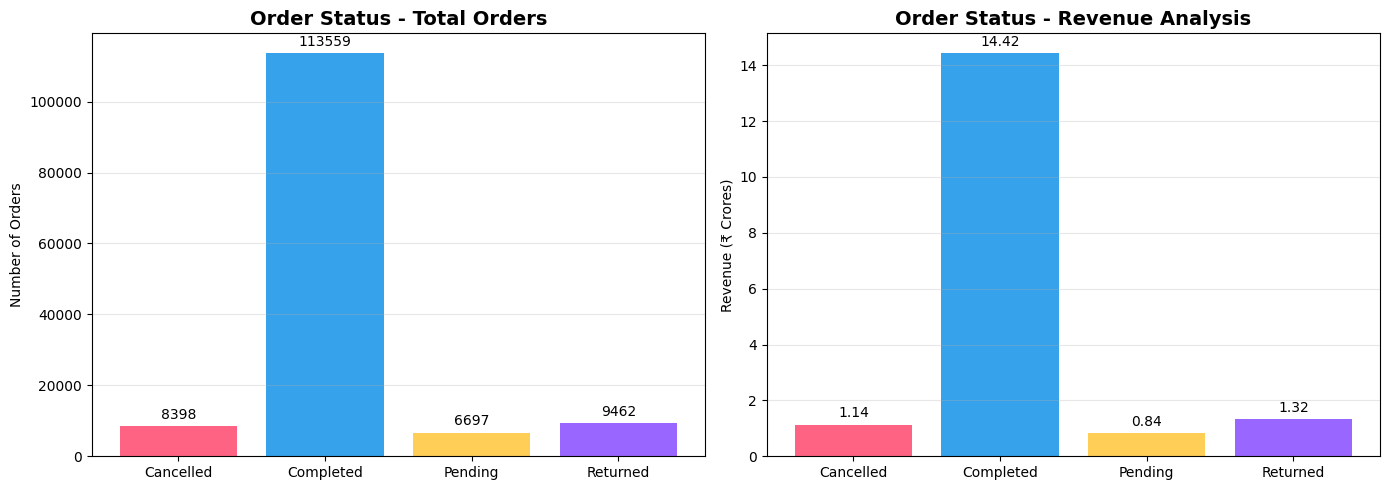

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#FF6384', '#36A2EB', '#FFCE56', '#9966FF']

# Order Count Chart
bars1 = axes[0].bar(
    order_status_analysis['order_status'],
    order_status_analysis['Total_Orders'],
    color=colors
)

axes[0].set_title('Order Status - Total Orders',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Orders')
axes[0].bar_label(bars1, padding=3)

# Revenue Chart
bars2 = axes[1].bar(
    order_status_analysis['order_status'],
    order_status_analysis['Total_Revenue'] / 10000000,
    color=colors
)

axes[1].set_title('Order Status - Revenue Analysis',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Revenue (₹ Crores)')
axes[1].bar_label(bars2, fmt='%.2f', padding=3)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Completed orders have the highest order count of 113,559.

2. Completed orders generate the highest revenue of ₹14.42 Crores.

3. Cancelled orders account for 8,398 orders.

4. Pending orders account for 6,697 orders.

5. Returned orders account for 9,462 orders.

6. Completed orders represent approximately 82.2% of all orders.

7. Returned orders have higher revenue than cancelled and pending orders.

# 20. Payment Status Analysis

This analysis examines different payment statuses to understand successful, pending, and failed payment transactions.

In [ ]:
payment_status_analysis = df.groupby('payment_status').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(payment_status_analysis)

,payment_status,Total_Orders,Total_Revenue,Total_Profit
0,Failed,10429,1.387934e+07,7031871.34
1,Paid,104250,1.324513e+08,54879681.81
2,Pending,13975,1.763097e+07,7309245.21
3,Refunded,9462,1.317267e+07,6925597.40


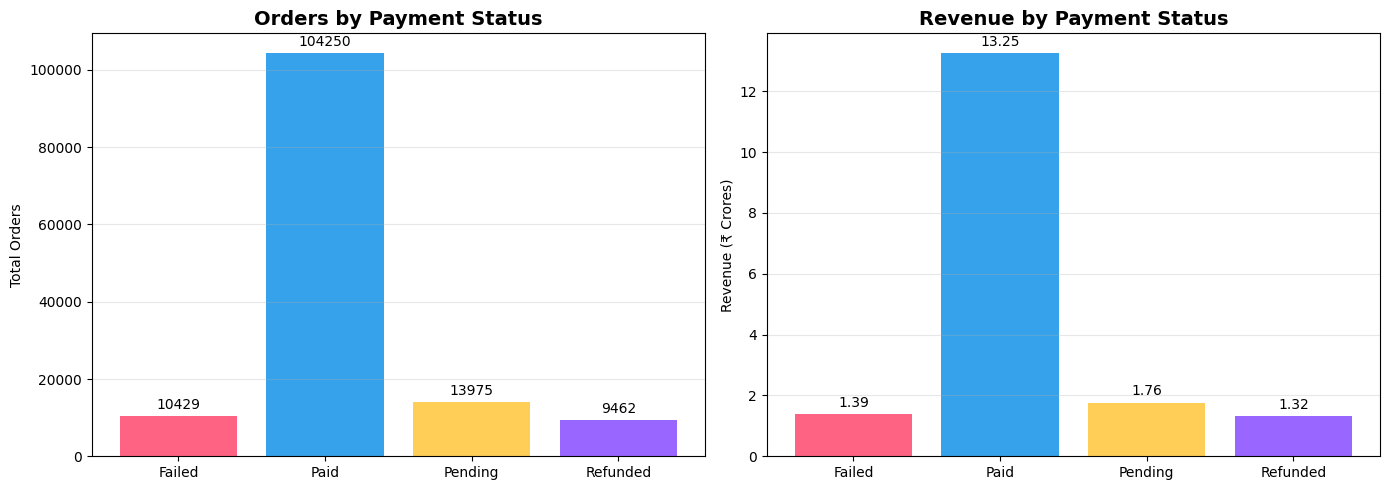

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#FF6384', '#36A2EB', '#FFCE56', '#9966FF']

# Chart 1: Payment Status - Orders
bars1 = axes[0].bar(
    payment_status_analysis['payment_status'],
    payment_status_analysis['Total_Orders'],
    color=colors
)

axes[0].set_title('Orders by Payment Status',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Orders')
axes[0].bar_label(bars1, padding=3)

# Chart 2: Payment Status - Revenue
bars2 = axes[1].bar(
    payment_status_analysis['payment_status'],
    payment_status_analysis['Total_Revenue'] / 10000000,
    color=colors
)

axes[1].set_title('Revenue by Payment Status',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Revenue (₹ Crores)')
axes[1].bar_label(bars2, fmt='%.2f', padding=3)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Paid transactions have the highest number of orders (104,250).

2. Paid transactions generate the highest revenue of ₹13.25 Crores.

3. Pending payments account for 13,975 orders.

4. Failed payments account for 10,429 orders.

5. Refunded transactions account for 9,462 orders.

6. Pending payments contribute ₹1.76 Crores in recorded revenue.

7. Paid transactions represent approximately 75.5% of total orders.

8. Payment monitoring is important to reduce failed and pending transactions.

# 21. Delivery Status Analysis

This analysis examines delivery performance by comparing order counts, revenue, and profit across different delivery statuses.

In [ ]:
delivery_analysis = df.groupby('delivery_status').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(delivery_analysis)

,delivery_status,Total_Orders,Total_Revenue,Total_Profit
0,Cancelled,24557,3.293843e+07,16387926.73
1,Delayed,16886,2.145506e+07,8876468.15
2,Early,9757,1.244488e+07,5194094.59
3,On Time,86916,1.102959e+08,45687906.29


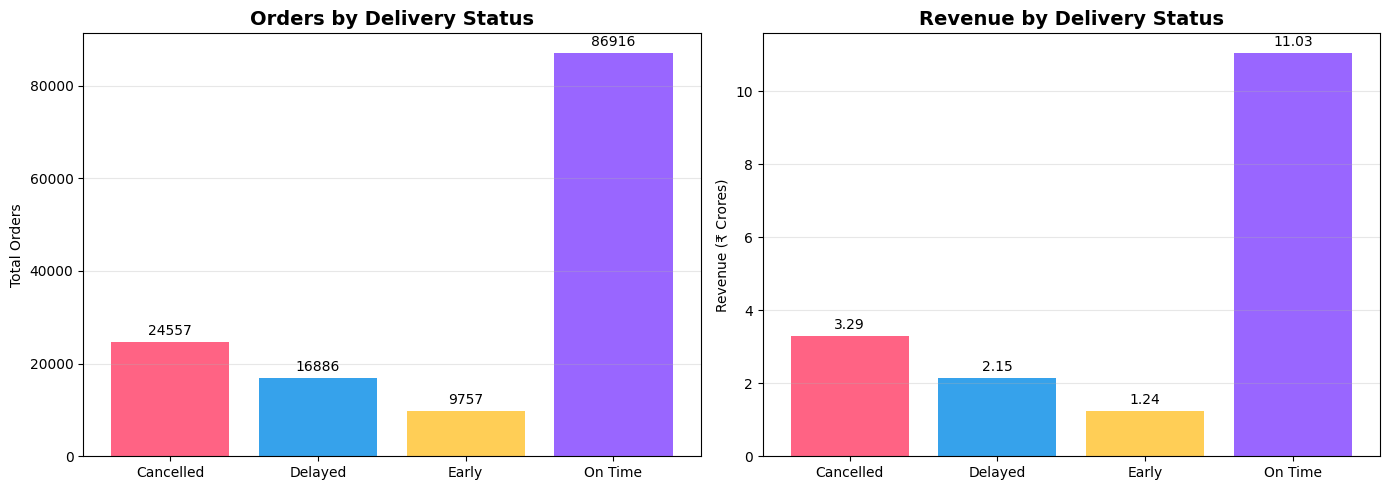

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#FF6384', '#36A2EB', '#FFCE56', '#9966FF']

# Orders Chart
bars1 = axes[0].bar(
    delivery_analysis['delivery_status'],
    delivery_analysis['Total_Orders'],
    color=colors
)

axes[0].set_title('Orders by Delivery Status',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Orders')
axes[0].bar_label(bars1, padding=3)

# Revenue Chart
bars2 = axes[1].bar(
    delivery_analysis['delivery_status'],
    delivery_analysis['Total_Revenue'] / 10000000,
    color=colors
)

axes[1].set_title('Revenue by Delivery Status',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Revenue (₹ Crores)')
axes[1].bar_label(bars2, fmt='%.2f', padding=3)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. On Time deliveries have the highest number of orders (86,916).

2. On Time deliveries generate the highest revenue of ₹11.03 Crores.

3. Cancelled deliveries account for 24,557 orders.

4. Delayed deliveries account for 16,886 orders.

5. Early deliveries account for 9,757 orders.

6. Cancelled deliveries contribute ₹3.29 Crores in recorded revenue.

7. Approximately 62.9% of orders are delivered On Time.

8. Cancelled orders represent an important area for further analysis.

# 22. Return Status Analysis

This analysis examines returned and non-returned orders to understand product return patterns and their impact on revenue and profit.

In [ ]:
return_analysis = df.groupby('return_status').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(return_analysis)

,return_status,Total_Orders,Total_Revenue,Total_Profit
0,Not Returned,128654,1.639616e+08,69220798.36
1,Returned,9462,1.317267e+07,6925597.40


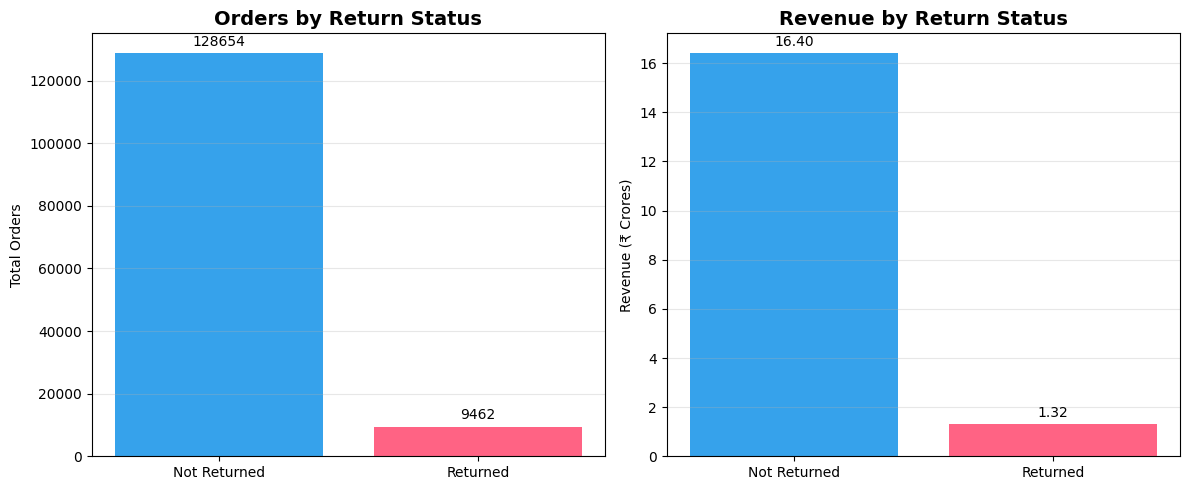

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors = ['#36A2EB', '#FF6384']

# Orders Chart
bars1 = axes[0].bar(
    return_analysis['return_status'],
    return_analysis['Total_Orders'],
    color=colors
)

axes[0].set_title('Orders by Return Status',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Orders')
axes[0].bar_label(bars1, padding=3)

# Revenue Chart
bars2 = axes[1].bar(
    return_analysis['return_status'],
    return_analysis['Total_Revenue'] / 10000000,
    color=colors
)

axes[1].set_title('Revenue by Return Status',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Revenue (₹ Crores)')
axes[1].bar_label(bars2, fmt='%.2f', padding=3)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Not Returned orders have the highest count of 128,654.

2. Returned orders account for 9,462 orders.

3. Approximately 93.2% of orders are Not Returned.

4. Only 6.8% of orders are Returned.

5. Not Returned orders generate revenue of ₹16.40 Crores.

6. Returned orders contribute revenue of ₹1.32 Crores.

7. Not Returned orders contribute the majority of total revenue.

8. Return rate is relatively low compared to non-returned orders.

# 23. Marketing Channel Analysis

This analysis compares revenue, profit, and order count across different marketing channels to understand their contribution to business performance.

In [ ]:
marketing_analysis = df.groupby('marketing_channel').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(marketing_analysis)

,marketing_channel,Total_Orders,Total_Revenue,Total_Profit
0,Affiliate,6848,8827899.78,3805557.93
1,Direct,20515,26117885.52,11280316.74
2,Email Marketing,11218,14420446.43,6177791.79
3,Facebook Ads,16651,21372470.11,9189184.91
4,Google Ads,20633,26540586.44,11356389.55
5,Instagram,13801,17676446.46,7585410.75
6,Organic Search,27742,35658209.46,15313174.30
7,Referral,11191,14342124.81,6186481.45
8,TikTok,5437,6980204.06,3011928.49
9,YouTube,4080,5197990.67,2240159.85


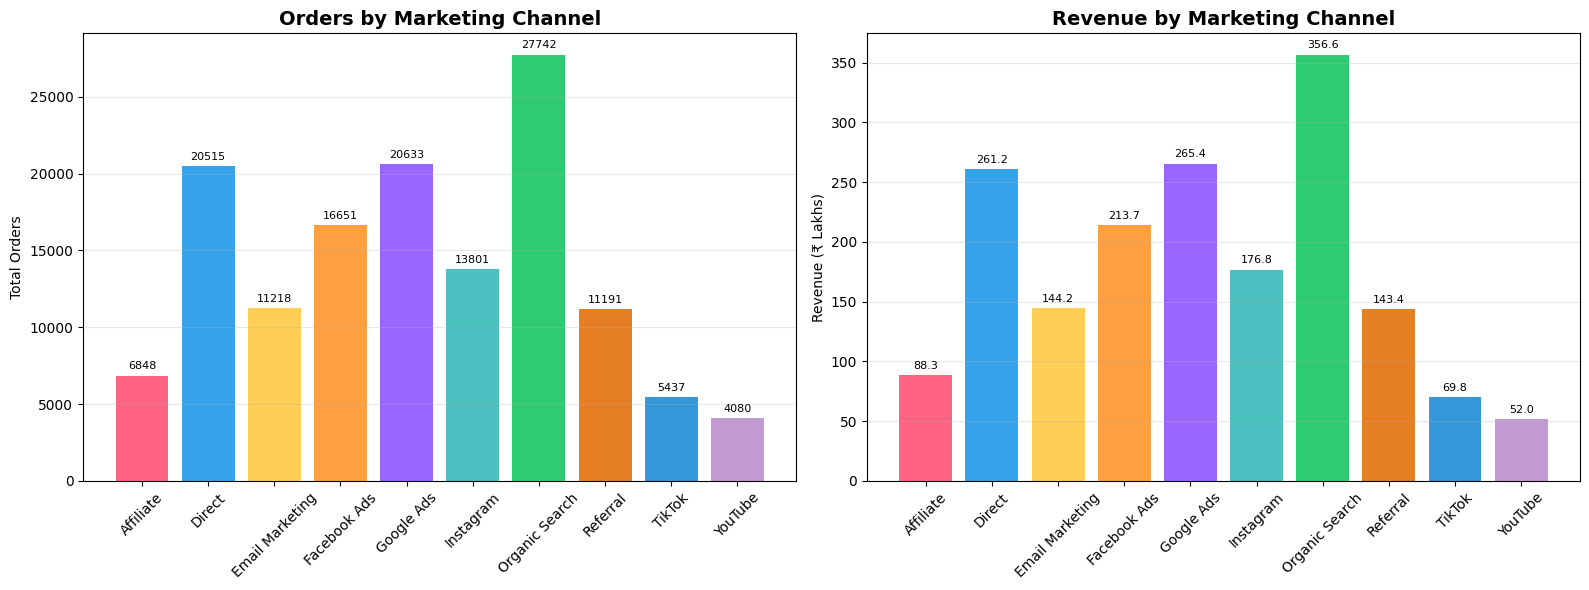

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['#FF6384', '#36A2EB', '#FFCE56', '#FF9F40',
          '#9966FF', '#4BC0C0', '#2ECC71', '#E67E22',
          '#3498DB', '#C39BD3']

# Orders Chart
bars1 = axes[0].bar(
    marketing_analysis['marketing_channel'],
    marketing_analysis['Total_Orders'],
    color=colors
)

axes[0].set_title('Orders by Marketing Channel',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Orders')
axes[0].tick_params(axis='x', rotation=45)
axes[0].bar_label(bars1, padding=3, fontsize=8)

# Revenue Chart
bars2 = axes[1].bar(
    marketing_analysis['marketing_channel'],
    marketing_analysis['Total_Revenue'] / 100000,
    color=colors
)

axes[1].set_title('Revenue by Marketing Channel',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Revenue (₹ Lakhs)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].bar_label(bars2, fmt='%.1f', padding=3, fontsize=8)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Organic Search generates the highest number of orders (27,742).

2. Organic Search generates the highest revenue of ₹356.58 Lakhs.

3. Organic Search also contributes the highest profit of ₹153.13 Lakhs.

4. Google Ads generates 20,633 orders and ₹265.41 Lakhs in revenue.

5. Direct Marketing generates 20,515 orders and ₹261.18 Lakhs in revenue.

6. YouTube has the lowest order count with 4,080 orders.

7. YouTube generates the lowest revenue of ₹51.98 Lakhs.

8. Organic Search is the best-performing marketing channel based on revenue, profit, and order count.

# 24. Customer Type Analysis

This analysis compares revenue, profit, and order count across different customer types to understand purchasing behaviour and customer contribution.

In [ ]:
customer_type_analysis = df.groupby('customer_type').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(customer_type_analysis)

,customer_type,Total_Orders,Total_Revenue,Total_Profit
0,Loyal,129447,1.661754e+08,71438627.72
1,New,334,4.354568e+05,192740.73
2,Returning,8335,1.052336e+07,4515027.31


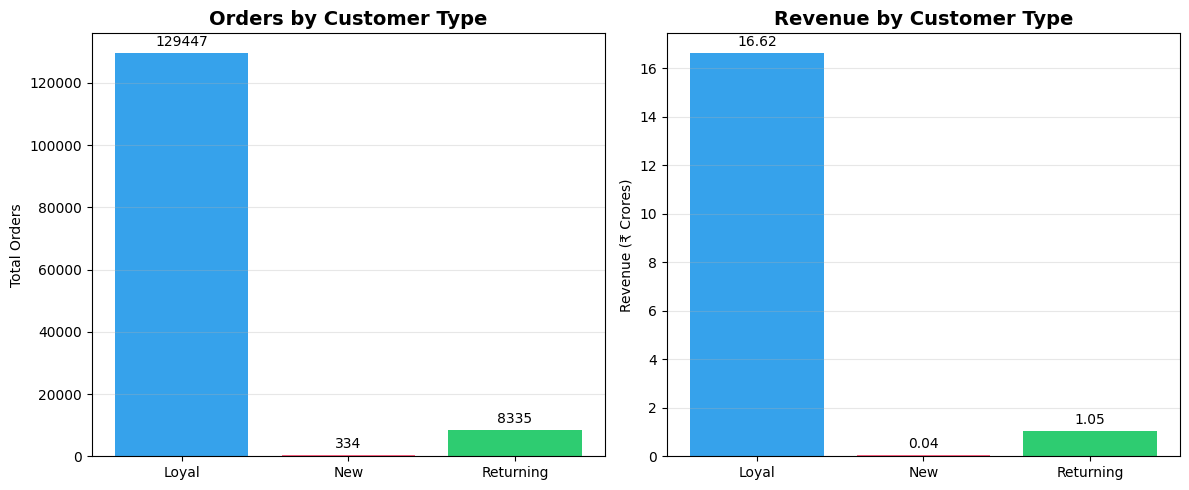

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors = ['#36A2EB', '#FF6384', '#2ECC71']

# Orders Chart
bars1 = axes[0].bar(
    customer_type_analysis['customer_type'],
    customer_type_analysis['Total_Orders'],
    color=colors
)

axes[0].set_title('Orders by Customer Type',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Orders')
axes[0].bar_label(bars1, padding=3)

# Revenue Chart
bars2 = axes[1].bar(
    customer_type_analysis['customer_type'],
    customer_type_analysis['Total_Revenue'] / 10000000,
    color=colors
)

axes[1].set_title('Revenue by Customer Type',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Revenue (₹ Crores)')
axes[1].bar_label(bars2, fmt='%.2f', padding=3)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Loyal customers contribute the highest number of orders (129,447).

2. Loyal customers generate the highest revenue of ₹16.62 Crores.

3. Loyal customers contribute the highest profit of ₹7.14 Crores.

4. Returning customers contribute 8,335 orders and ₹1.05 Crores in revenue.

5. New customers account for only 334 orders.

6. Loyal customers represent approximately 93.7% of total orders.

7. Customer revenue is highly concentrated among loyal customers.

8. Returning and new customers represent opportunities to study future customer growth.

# 25. Shipping Method Analysis

This analysis compares revenue, profit, and order count across different shipping methods to understand their contribution to e-commerce performance.

In [ ]:
shipping_analysis = df.groupby('shipping_method').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(shipping_analysis)

,shipping_method,Total_Orders,Total_Revenue,Total_Profit
0,Economy,27824,35637406.57,15345705.07
1,Express,34373,44003664.18,18847987.11
2,Same Day,13913,18023854.99,7640416.56
3,Standard,62006,79469338.00,34312287.02


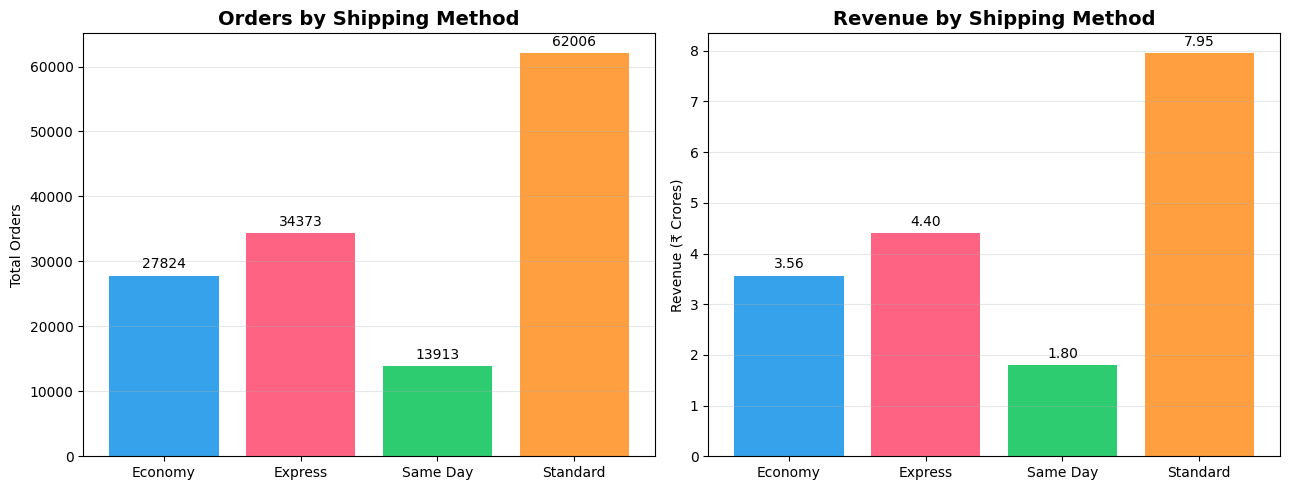

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ['#36A2EB', '#FF6384', '#2ECC71', '#FF9F40']

# Orders Chart
bars1 = axes[0].bar(
    shipping_analysis['shipping_method'],
    shipping_analysis['Total_Orders'],
    color=colors
)

axes[0].set_title('Orders by Shipping Method',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Orders')
axes[0].bar_label(bars1, padding=3)

# Revenue Chart
bars2 = axes[1].bar(
    shipping_analysis['shipping_method'],
    shipping_analysis['Total_Revenue'] / 10000000,
    color=colors
)

axes[1].set_title('Revenue by Shipping Method',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Revenue (₹ Crores)')
axes[1].bar_label(bars2, fmt='%.2f', padding=3)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Standard shipping has the highest number of orders (62,006).

2. Standard shipping generates the highest revenue of ₹7.95 Crores.

3. Standard shipping contributes the highest profit of ₹3.43 Crores.

4. Express shipping records 34,373 orders and ₹4.40 Crores in revenue.

5. Economy shipping contributes 27,824 orders and ₹3.56 Crores in revenue.

6. Same Day shipping has the lowest order count (13,913).

7. Same Day shipping generates ₹1.80 Crores in revenue.

8. Standard shipping is the leading shipping method in terms of orders, revenue, and profit.

In [ ]:
products = pd.read_csv('/content/ecommerce_data/product_catalog.csv')
items = pd.read_csv('/content/ecommerce_data/order_items.csv')

print("PRODUCT CATALOG")
display(products.head())

print("ORDER ITEMS")
display(items.head())

print("Product Columns:", products.columns.tolist())
print("Order Item Columns:", items.columns.tolist())

PRODUCT CATALOG


,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.90,474.06,4.3
1,PROD-000002,Google User-centric even-keeled encryption Sma...,Electronics,Smartphones,Google,Euro Logistics,978.26,519.66,2.9
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.51,185.48,3.9
3,PROD-000004,Sony Customer-focused systematic support Smart...,Electronics,Smartphones,Sony,Amazon Supply,1120.49,564.86,4.8
4,PROD-000005,OnePlus Quality-focused background parallelism...,Electronics,Smartphones,OnePlus,Direct Import,1282.18,695.54,2.9


ORDER ITEMS


,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53


Product Columns: ['product_id', 'product_name', 'product_category', 'product_subcategory', 'brand', 'supplier', 'unit_price', 'product_cost', 'product_rating']
Order Item Columns: ['order_id', 'product_id', 'quantity', 'unit_price', 'discount_percentage', 'discount_amount', 'gross_sales', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit']


In [ ]:
product_data = items.merge(
    products,
    on='product_id',
    how='left'
)

print("Merged Dataset Shape:", product_data.shape)
display(product_data.head())

Merged Dataset Shape: (397569, 20)


,order_id,product_id,quantity,unit_price_x,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost_x,profit,product_name,product_category,product_subcategory,brand,supplier,unit_price_y,product_cost_y,product_rating
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12,Garmin Total client-driven task-force Medical ...,Health & Wellness,Medical Devices,Garmin,Euro Logistics,244.40,86.64,4.8
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92,Tommy Hilfiger Open-architected full-range foc...,Fashion,Shoes,Tommy Hilfiger,Pacific Trade,287.13,138.35,3.0
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84,Swarovski Re-engineered discrete monitoring Ea...,Jewelry,Earrings,Swarovski,MultiSource,754.80,494.04,3.5
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37,NARS Enterprise-wide actuating firmware Fragra...,Beauty & Personal Care,Fragrances,NARS,Global Trade,31.36,13.93,4.0
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53,Mars Multi-tiered homogeneous artificial intel...,Grocery,Pantry Staples,Mars,Asian Manufacturing,6.31,1.97,3.0


In [ ]:
product_category_analysis = product_data.groupby('product_category').agg(
    Total_Quantity=('quantity', 'sum'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(product_category_analysis)

,product_category,Total_Quantity,Total_Revenue,Total_Profit
0,Automotive,58046,16449898.28,6477194.28
1,Baby & Kids,53945,9690605.60,4818148.07
2,Beauty & Personal Care,59765,4735647.66,2477469.89
3,Books & Media,62305,2840799.90,1475496.28
4,Electronics,55784,41148162.90,14103982.74
5,Fashion,48774,7434589.51,3669631.60
6,Grocery,55607,2990696.44,1648934.90
7,Health & Wellness,62054,9228068.04,4263304.41
8,Home & Kitchen,49682,10971629.82,5203824.25
9,Home Appliances,56281,24842478.64,10288878.45


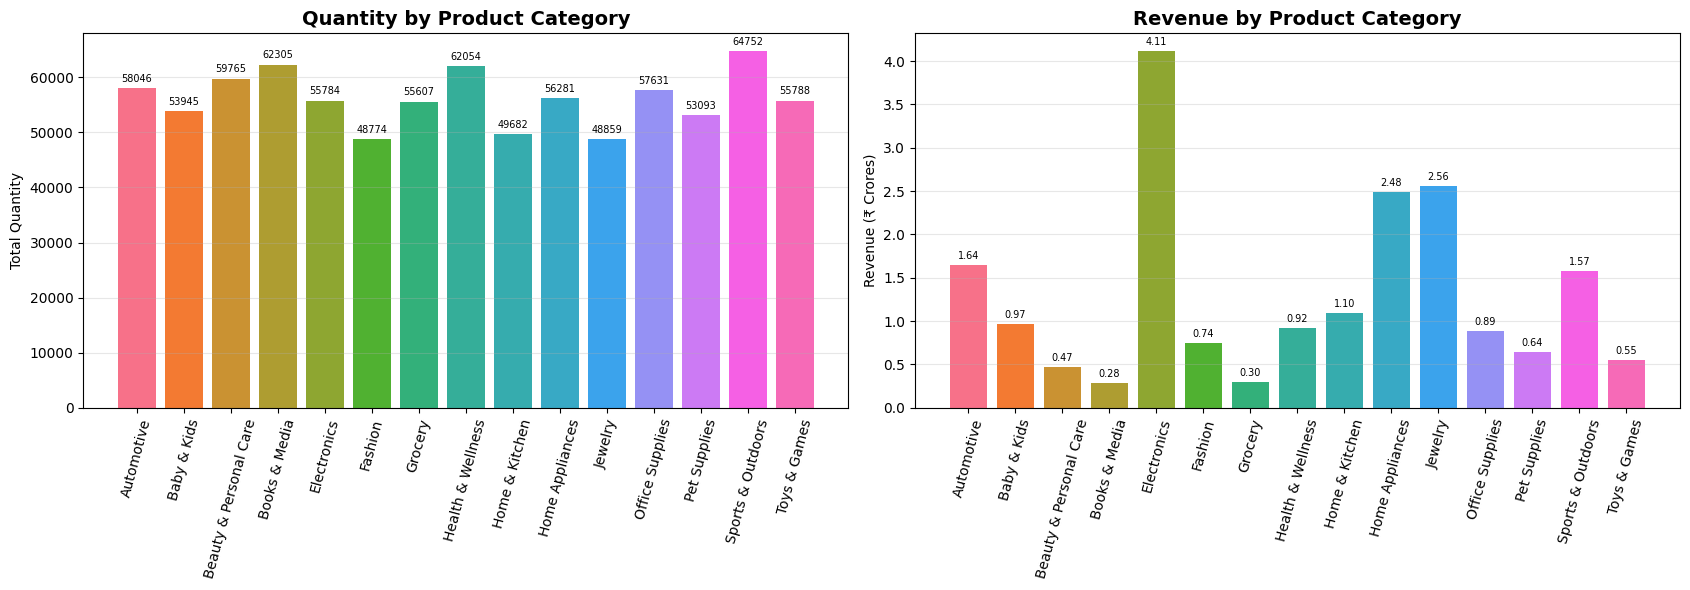

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

colors = sns.color_palette("husl", len(product_category_analysis))

# Quantity Chart
bars1 = axes[0].bar(
    product_category_analysis['product_category'],
    product_category_analysis['Total_Quantity'],
    color=colors
)

axes[0].set_title('Quantity by Product Category',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Quantity')
axes[0].tick_params(axis='x', rotation=75)
axes[0].bar_label(bars1, fmt='%.0f', padding=3, fontsize=7)

# Revenue Chart
bars2 = axes[1].bar(
    product_category_analysis['product_category'],
    product_category_analysis['Total_Revenue'] / 10000000,
    color=colors
)

axes[1].set_title('Revenue by Product Category',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Revenue (₹ Crores)')
axes[1].tick_params(axis='x', rotation=75)
axes[1].bar_label(bars2, fmt='%.2f', padding=3, fontsize=7)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Electronics generates the highest revenue of ₹4.11 Crores.

2. Electronics also contributes the highest profit of ₹1.41 Crores.

3. Sports & Outdoors has the highest sales quantity of 64,752 units.

4. Jewelry generates ₹2.56 Crores in revenue and ₹1.04 Crores in profit.

5. Home Appliances generates ₹2.48 Crores in revenue and ₹1.03 Crores in profit.

6. Automotive contributes ₹1.64 Crores in revenue.

7. Beauty & Personal Care has the lowest revenue of ₹47.36 Lakhs.

8. Books & Media generates the lowest profit of approximately ₹14.75 Lakhs.

9. Electronics is the strongest category in terms of revenue and profit.

10. Sports & Outdoors leads in quantity sold.

# 27. Brand-wise Performance Analysis

This analysis compares different product brands based on total quantity sold, revenue, and profit to identify the best-performing brands.

In [ ]:
brand_analysis = product_data.groupby('brand').agg(
    Total_Quantity=('quantity', 'sum'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

brand_analysis = brand_analysis.sort_values(
    by='Total_Revenue', ascending=False
)

display(brand_analysis)

,brand,Total_Quantity,Total_Revenue,Total_Profit
116,Samsung,11402,6922013.66,2435719.85
65,LG,11652,6165232.04,2166500.26
92,OnePlus,6540,5080134.21,1837015.90
4,Asus,4985,4831788.72,1615392.91
49,HP,7071,4550295.21,1673770.51
...,...,...,...,...
111,Random House,4201,207741.71,114287.60
87,Nestle,4138,204716.74,114028.95
59,Kellogg's,3707,175955.64,96609.49
72,Mars,4845,154732.27,74205.87


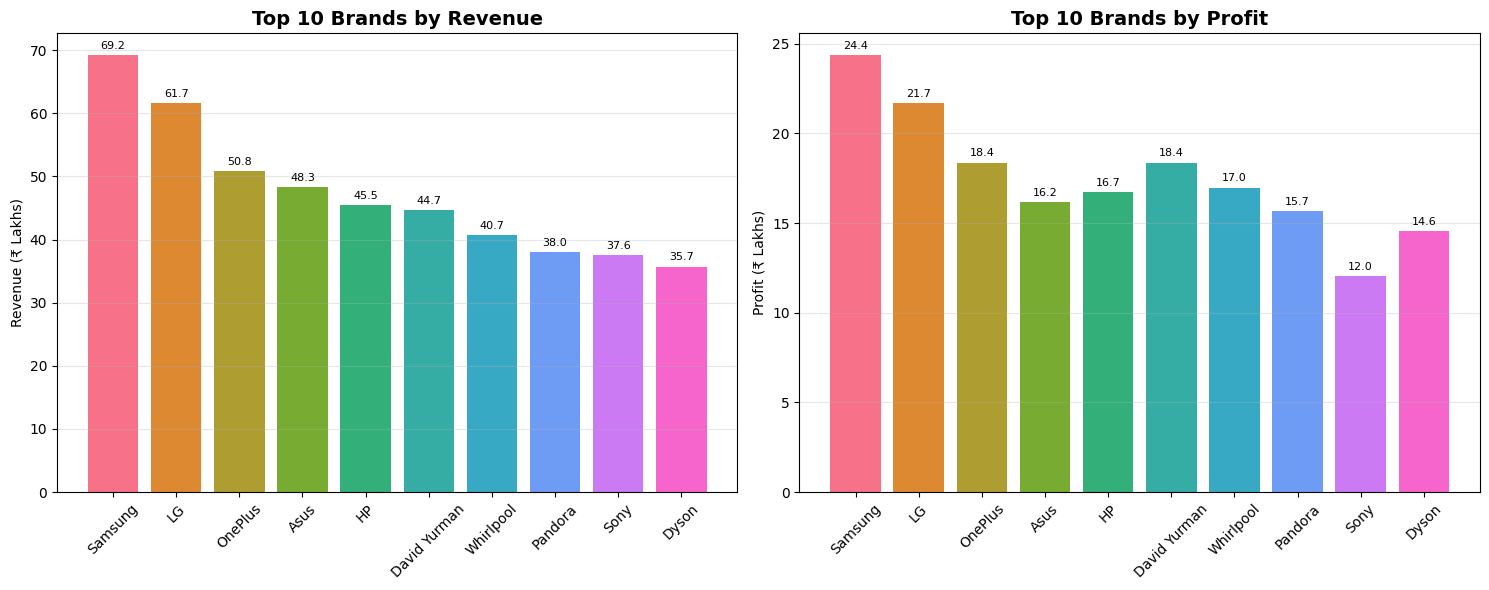

In [ ]:
top_brands = brand_analysis.head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = sns.color_palette("husl", 10)

# Revenue Chart
bars1 = axes[0].bar(
    top_brands['brand'],
    top_brands['Total_Revenue'] / 100000,
    color=colors
)

axes[0].set_title('Top 10 Brands by Revenue',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Revenue (₹ Lakhs)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].bar_label(bars1, fmt='%.1f', padding=3, fontsize=8)

# Profit Chart
bars2 = axes[1].bar(
    top_brands['brand'],
    top_brands['Total_Profit'] / 100000,
    color=colors
)

axes[1].set_title('Top 10 Brands by Profit',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Profit (₹ Lakhs)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].bar_label(bars2, fmt='%.1f', padding=3, fontsize=8)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Samsung generates the highest revenue of ₹69.22 Lakhs among all brands.

2. Samsung also records the highest profit of ₹24.36 Lakhs.

3. LG ranks second in revenue with ₹61.65 Lakhs.

4. LG has the highest quantity sold with 11,652 units.

5. OnePlus ranks third in revenue with ₹50.80 Lakhs and profit of ₹18.37 Lakhs.

6. Asus generates ₹48.32 Lakhs in revenue.

7. HP contributes ₹45.50 Lakhs in revenue and ₹16.74 Lakhs in profit.

8. Spin Master has the lowest revenue of ₹1.33 Lakhs among the listed brands.

9. Samsung is the leading brand in revenue and profit.

10. Brand performance varies significantly across the 144 brands.

# 28. Supplier-wise Performance Analysis

This analysis compares suppliers based on total quantity sold, revenue, and profit to understand supplier performance.

In [ ]:
supplier_analysis = product_data.groupby('supplier').agg(
    Total_Quantity=('quantity', 'sum'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

supplier_analysis = supplier_analysis.sort_values(
    by='Total_Revenue', ascending=False
)

display(supplier_analysis)

,supplier,Total_Quantity,Total_Revenue,Total_Profit
1,Amazon Supply,90868,23154636.33,9546695.70
7,MultiSource,102303,22738376.05,9880413.51
4,Domestic Producers,88349,21396317.76,9449405.08
5,Euro Logistics,85660,21134491.91,9020243.40
3,Direct Import,87712,20765695.44,8876967.88
8,North American Supply,92744,19176464.43,8749324.43
9,Pacific Trade,75823,17395848.18,7548726.59
2,Asian Manufacturing,74462,16909705.61,6816651.12
6,Global Trade,76030,15487741.62,6794419.79
0,Alibaba,68415,14239599.96,6015191.05


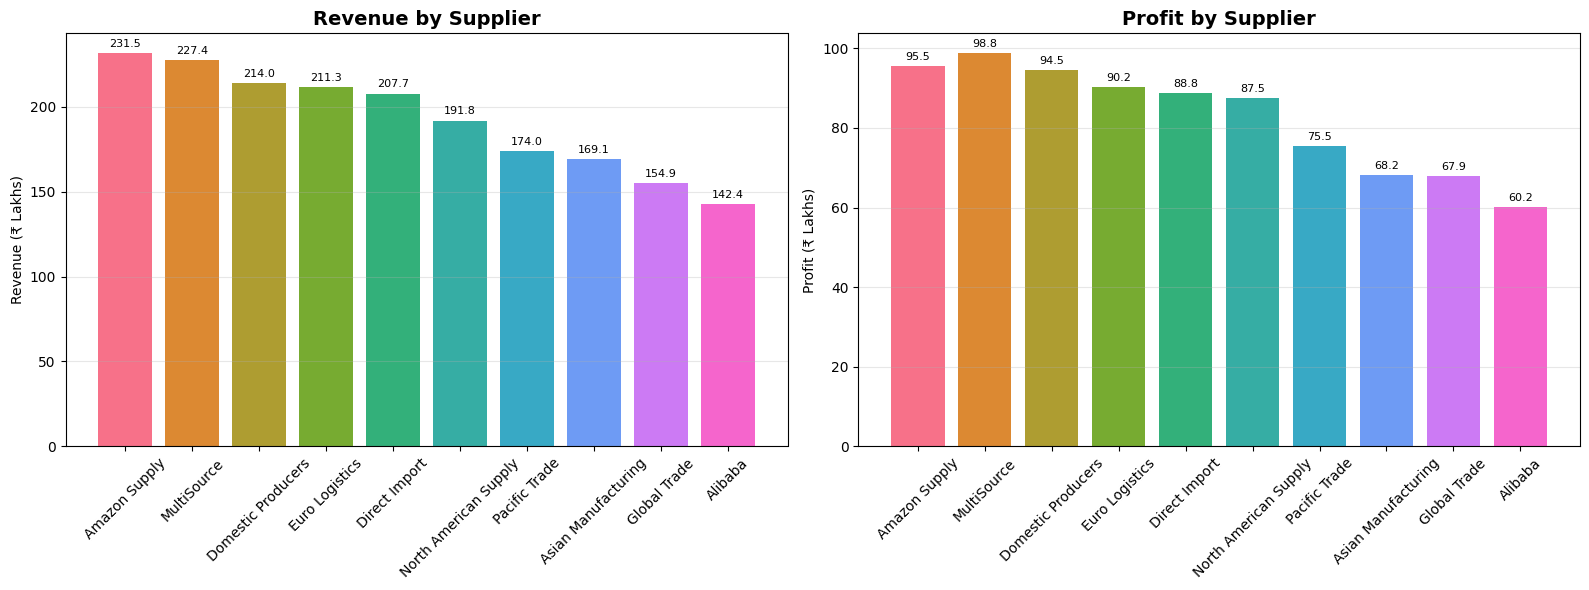

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = sns.color_palette("husl", len(supplier_analysis))

# Revenue Chart
bars1 = axes[0].bar(
    supplier_analysis['supplier'],
    supplier_analysis['Total_Revenue'] / 100000,
    color=colors
)

axes[0].set_title('Revenue by Supplier',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Revenue (₹ Lakhs)')
axes[0].tick_params(axis='x', rotation=45)
bars1_values = [f'{v:.1f}' for v in supplier_analysis['Total_Revenue'] / 100000]
axes[0].bar_label(bars1, labels=bars1_values, padding=3, fontsize=8)

# Profit Chart
bars2 = axes[1].bar(
    supplier_analysis['supplier'],
    supplier_analysis['Total_Profit'] / 100000,
    color=colors
)

axes[1].set_title('Profit by Supplier',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Profit (₹ Lakhs)')
axes[1].tick_params(axis='x', rotation=45)
bars2_values = [f'{v:.1f}' for v in supplier_analysis['Total_Profit'] / 100000]
axes[1].bar_label(bars2, labels=bars2_values, padding=3, fontsize=8)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Amazon Supply generates the highest revenue of ₹231.55 Lakhs.

2. MultiSource records the highest profit of ₹98.80 Lakhs.

3. MultiSource has the highest quantity sold with 102,303 units.

4. Domestic Producers ranks third in revenue with ₹213.96 Lakhs.

5. Euro Logistics generates ₹211.34 Lakhs in revenue.

6. North American Supply contributes 92,744 units in quantity.

7. Alibaba has the lowest revenue of ₹142.40 Lakhs.

8. Alibaba also records the lowest profit of ₹60.15 Lakhs.

9. Amazon Supply and MultiSource are strong-performing suppliers.

10. Supplier performance varies in terms of revenue, profit, and quantity.

# 29. Customer Purchase Behaviour Analysis

This analysis studies customer purchasing behaviour using order frequency, total revenue, total profit, and customer lifetime value.

In [ ]:
customer_behavior = df.groupby('customer_id').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum'),
    Customer_Lifetime_Value=('customer_lifetime_value', 'first')
).reset_index()

display(customer_behavior.head(10))

,customer_id,Total_Orders,Total_Revenue,Total_Profit,Customer_Lifetime_Value
0,CUST-000001,9,9924.84,3894.40,11125.84
1,CUST-000002,10,18138.96,9138.59,18138.96
2,CUST-000003,7,7798.59,3871.98,7798.59
3,CUST-000004,7,11218.95,3745.70,11218.95
4,CUST-000005,8,10063.97,4021.66,10063.97
5,CUST-000006,7,9284.89,4946.92,12963.67
6,CUST-000007,4,7912.63,2741.54,10679.09
7,CUST-000008,8,4938.79,1441.60,4938.79
8,CUST-000009,4,2615.45,1157.11,2615.45
9,CUST-000010,4,9556.63,4090.35,9556.63


In [ ]:
print("Total Customers:", customer_behavior['customer_id'].nunique())
print("Average Orders per Customer:",
      round(customer_behavior['Total_Orders'].mean(), 2))
print("Average Customer Revenue:",
      round(customer_behavior['Total_Revenue'].mean(), 2))

Total Customers: 24911
Average Orders per Customer: 5.54
Average Customer Revenue: 7110.68


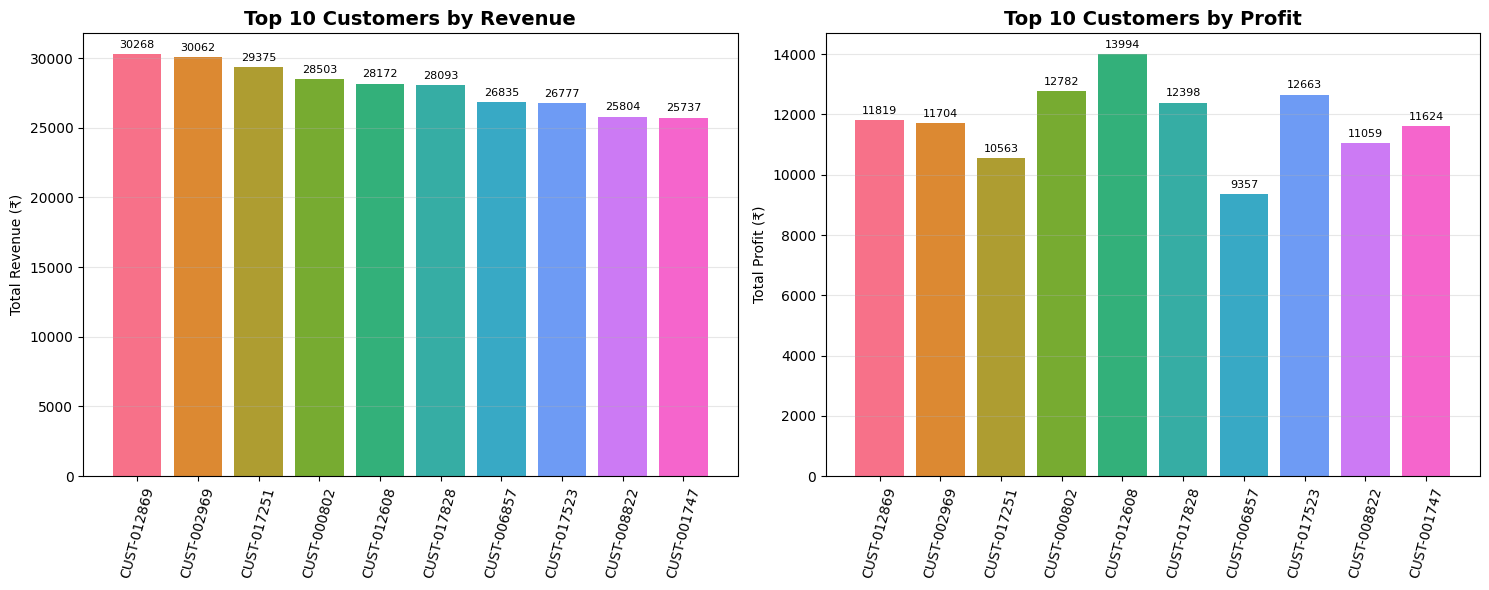

In [ ]:
top_customers = customer_behavior.nlargest(10, 'Total_Revenue')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = sns.color_palette("husl", 10)

# Revenue Chart
bars1 = axes[0].bar(
    top_customers['customer_id'],
    top_customers['Total_Revenue'],
    color=colors
)

axes[0].set_title('Top 10 Customers by Revenue',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Revenue (₹)')
axes[0].tick_params(axis='x', rotation=75)
axes[0].bar_label(bars1, fmt='%.0f', padding=3, fontsize=8)

# Profit Chart
bars2 = axes[1].bar(
    top_customers['customer_id'],
    top_customers['Total_Profit'],
    color=colors
)

axes[1].set_title('Top 10 Customers by Profit',
                  fontsize=14, fontweight='bold')
axes[1].set_ylabel('Total Profit (₹)')
axes[1].tick_params(axis='x', rotation=75)
axes[1].bar_label(bars2, fmt='%.0f', padding=3, fontsize=8)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Customer purchase frequency varies across customers.

2. In the first 10 displayed customers, CUST-000002 has the highest revenue of ₹18,138.96.

3. CUST-000002 also records the highest profit of ₹9,138.59 among the first 10 customers.

4. CUST-000009 has the lowest revenue of ₹2,615.45 among the first 10 customers.

5. CUST-000002 has placed 10 orders, the highest order count among the first 10 customers.

6. Customer lifetime value differs across individual customers.

7. CUST-000006 has a customer lifetime value of ₹12,963.67.

8. The analysis helps identify high-value customers and understand differences in purchasing behaviour.

# 30. Customer Rating Analysis

This analysis examines customer ratings to understand customer satisfaction and its relationship with sales performance.

In [ ]:
rating_analysis = df.groupby('customer_rating').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(rating_analysis)

,customer_rating,Total_Orders,Total_Revenue,Total_Profit
0,1.6,2,1526.42,845.54
1,1.7,3,2122.85,846.63
2,1.8,8,7180.16,3682.61
3,1.9,11,3887.33,1586.48
4,2.0,32,26311.58,10313.61
5,2.1,73,58299.16,24768.70
6,2.2,131,115305.45,50703.37
7,2.3,219,210004.20,88405.99
8,2.4,313,360455.93,154122.60
9,2.5,571,657782.17,272455.62


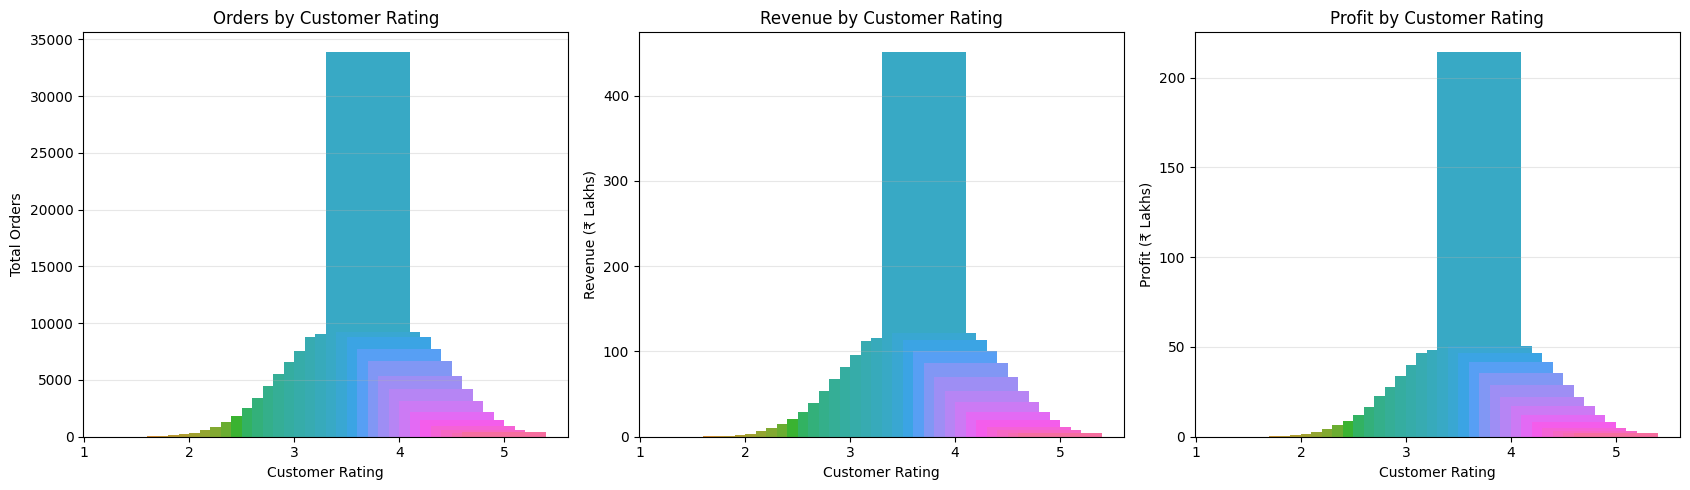

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

colors = sns.color_palette("husl", len(rating_analysis))

# Orders Chart
axes[0].bar(rating_analysis['customer_rating'],
            rating_analysis['Total_Orders'], color=colors)
axes[0].set_title('Orders by Customer Rating')
axes[0].set_xlabel('Customer Rating')
axes[0].set_ylabel('Total Orders')

# Revenue Chart
axes[1].bar(rating_analysis['customer_rating'],
            rating_analysis['Total_Revenue'] / 100000,
            color=colors)
axes[1].set_title('Revenue by Customer Rating')
axes[1].set_xlabel('Customer Rating')
axes[1].set_ylabel('Revenue (₹ Lakhs)')

# Profit Chart
axes[2].bar(rating_analysis['customer_rating'],
            rating_analysis['Total_Profit'] / 100000,
            color=colors)
axes[2].set_title('Profit by Customer Rating')
axes[2].set_xlabel('Customer Rating')
axes[2].set_ylabel('Profit (₹ Lakhs)')

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Customer ratings range from 1.6 to 5.0.

2. Rating 3.7 records the highest number of orders with 33,919 orders.

3. Rating 3.7 generates the highest revenue of ₹4.52 Crores.

4. Rating 3.7 also contributes the highest profit of ₹2.15 Crores.

5. Rating 3.6 records 9,085 orders and ₹1.16 Crores in revenue.

6. Rating 3.8 contributes 9,263 orders and ₹1.22 Crores in revenue.

7. Ratings between 3.5 and 4.0 show strong sales performance.

8. Very low ratings such as 1.6 and 1.7 have very few orders.

9. Customer rating analysis helps identify satisfaction patterns and areas for service improvement.

# 31. Review Sentiment Analysis

This analysis examines customer review sentiments to understand customer opinions and their relationship with sales performance.

In [ ]:
sentiment_analysis = df.groupby('review_sentiment').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(sentiment_analysis)

,review_sentiment,Total_Orders,Total_Revenue,Total_Profit
0,Negative,792,7.850931e+05,335275.53
1,Neutral,34684,4.204868e+07,17513359.56
2,No Review,24557,3.293843e+07,16387926.73
3,Positive,78083,1.013621e+08,41909833.94


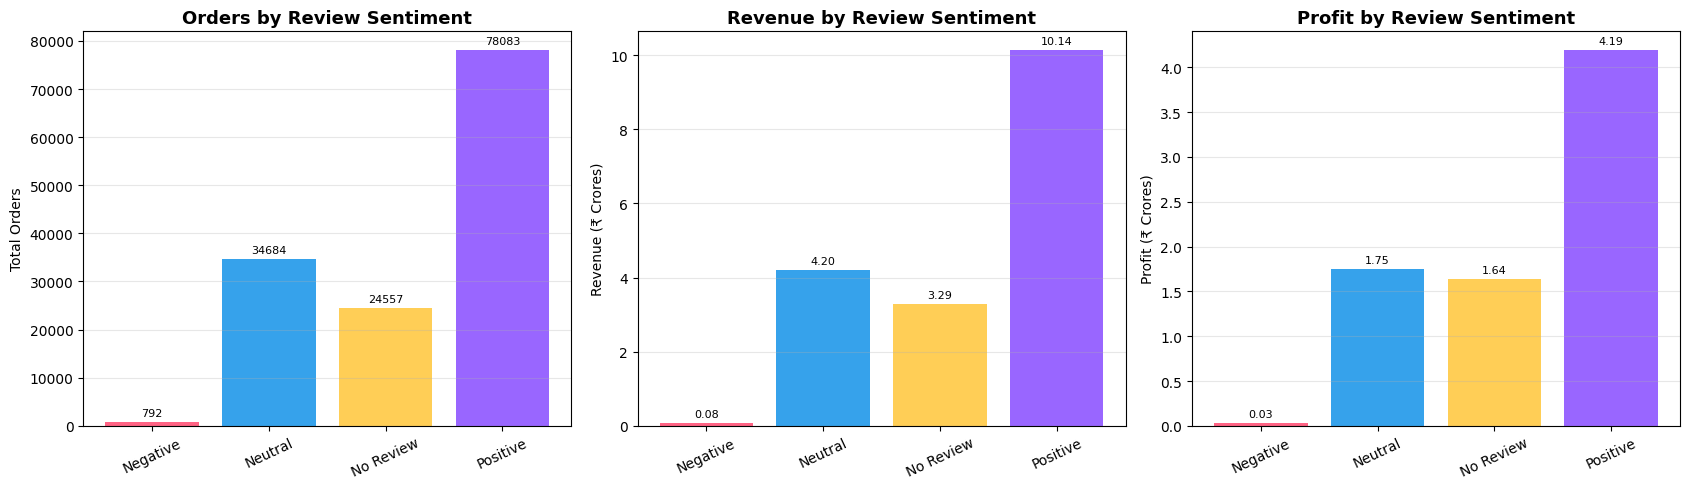

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

colors = ['#FF6384', '#36A2EB', '#FFCE56', '#9966FF']

# Orders Chart
bars1 = axes[0].bar(
    sentiment_analysis['review_sentiment'],
    sentiment_analysis['Total_Orders'],
    color=colors
)
axes[0].set_title('Orders by Review Sentiment',
                  fontsize=13, fontweight='bold')
axes[0].set_ylabel('Total Orders')
axes[0].bar_label(bars1, padding=3, fontsize=8)

# Revenue Chart
bars2 = axes[1].bar(
    sentiment_analysis['review_sentiment'],
    sentiment_analysis['Total_Revenue'] / 10000000,
    color=colors
)
axes[1].set_title('Revenue by Review Sentiment',
                  fontsize=13, fontweight='bold')
axes[1].set_ylabel('Revenue (₹ Crores)')
axes[1].bar_label(bars2, fmt='%.2f', padding=3, fontsize=8)

# Profit Chart
bars3 = axes[2].bar(
    sentiment_analysis['review_sentiment'],
    sentiment_analysis['Total_Profit'] / 10000000,
    color=colors
)
axes[2].set_title('Profit by Review Sentiment',
                  fontsize=13, fontweight='bold')
axes[2].set_ylabel('Profit (₹ Crores)')
axes[2].bar_label(bars3, fmt='%.2f', padding=3, fontsize=8)

for ax in axes:
    ax.tick_params(axis='x', rotation=25)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Positive reviews account for the highest number of orders with 78,083 orders.

2. Positive sentiment generates the highest revenue of ₹10.14 Crores.

3. Positive reviews contribute the highest profit of ₹4.19 Crores.

4. Neutral reviews account for 34,684 orders and generate ₹4.20 Crores in revenue.

5. No Review records account for 24,557 orders and ₹3.29 Crores in revenue.

6. Negative reviews have the lowest order count with only 792 orders.

7. Negative sentiment generates approximately ₹7.85 Lakhs in revenue.

8. Positive reviews contribute approximately 56.5% of total orders.

9. The dataset shows a strong contribution from customers with positive reviews.

10. Customers without reviews should be studied separately to understand their feedback behaviour.

# 32. Discount Analysis

This analysis examines the impact of discount percentages on total orders, revenue, and profit to understand discount-related sales performance.

In [ ]:
product_data['Discount_Range'] = pd.cut(
    product_data['discount_percentage'],
    bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 1.01],
    labels=['0-10%', '10-20%', '20-30%',
            '30-40%', '40-50%', 'Above 50%'],
    include_lowest=True
)

discount_analysis = product_data.groupby(
    'Discount_Range', observed=False
).agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

display(discount_analysis)

,Discount_Range,Total_Orders,Total_Revenue,Total_Profit
0,0-10%,88957,83821557.20,42536121.29
1,10-20%,81372,58099538.58,25775830.90
2,20-30%,37507,24541492.54,9217266.99
3,30-40%,18413,13794439.68,3938113.43
4,40-50%,14583,9256880.20,1435924.75
5,Above 50%,5662,2884969.09,-205218.81


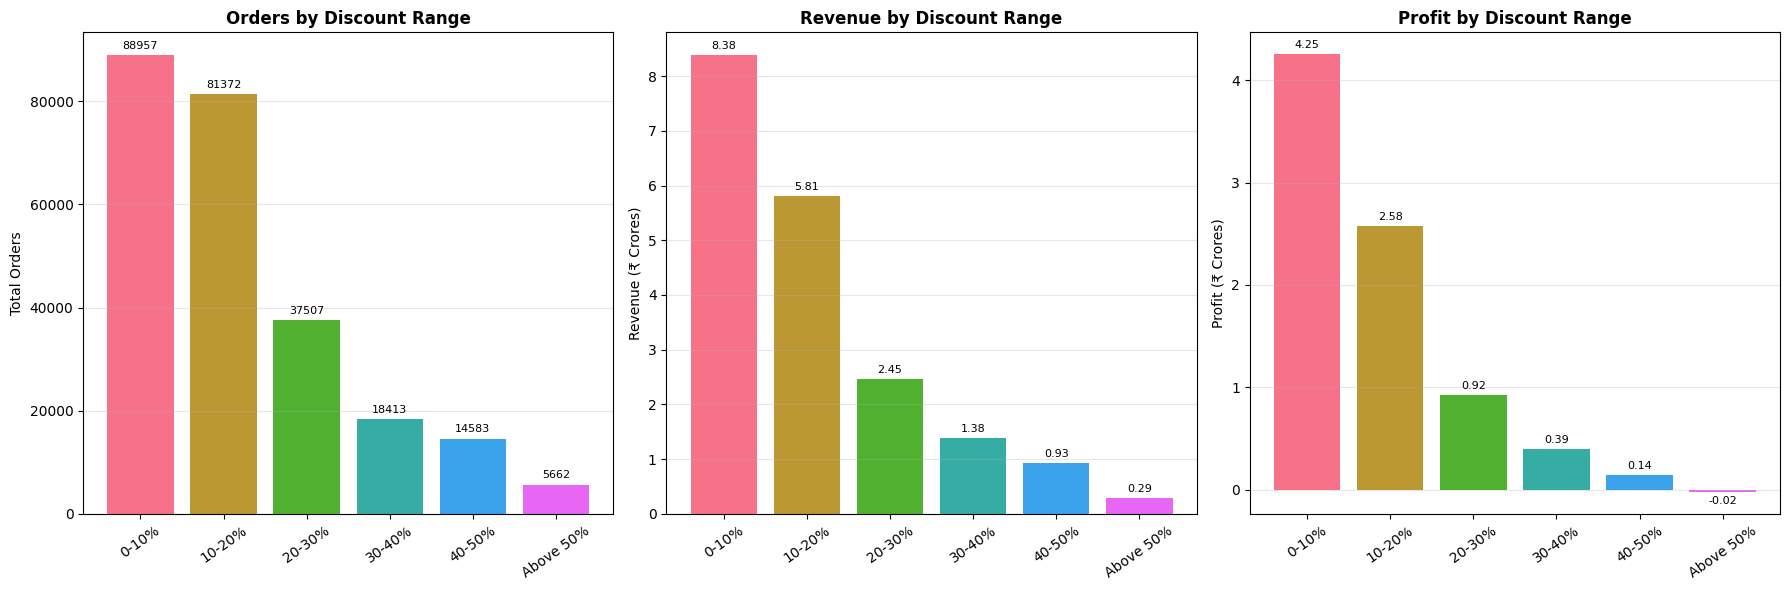

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

colors = sns.color_palette("husl", 6)
labels = discount_analysis['Discount_Range'].astype(str)

# Orders Chart
bars1 = axes[0].bar(
    labels, discount_analysis['Total_Orders'], color=colors
)
axes[0].set_title('Orders by Discount Range', fontweight='bold')
axes[0].set_ylabel('Total Orders')
axes[0].bar_label(bars1, fmt='%.0f', padding=3, fontsize=8)

# Revenue Chart
bars2 = axes[1].bar(
    labels, discount_analysis['Total_Revenue'] / 10000000,
    color=colors
)
axes[1].set_title('Revenue by Discount Range', fontweight='bold')
axes[1].set_ylabel('Revenue (₹ Crores)')
axes[1].bar_label(bars2, fmt='%.2f', padding=3, fontsize=8)

# Profit Chart
bars3 = axes[2].bar(
    labels, discount_analysis['Total_Profit'] / 10000000,
    color=colors
)
axes[2].set_title('Profit by Discount Range', fontweight='bold')
axes[2].set_ylabel('Profit (₹ Crores)')
axes[2].bar_label(bars3, fmt='%.2f', padding=3, fontsize=8)

for ax in axes:
    ax.tick_params(axis='x', rotation=35)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. The 0–10% discount range records the highest order count with 88,957 orders.

2. The 0–10% discount range generates the highest revenue of ₹8.38 Crores.

3. The 0–10% discount range contributes the highest profit of ₹4.25 Crores.

4. The 10–20% discount range generates ₹5.81 Crores in revenue and ₹2.58 Crores in profit.

5. Orders decrease as discount ranges increase.

6. The 40–50% discount range generates ₹92.57 Lakhs in revenue.

7. Discounts above 50% generate only ₹28.85 Lakhs in revenue.

8. Discounts above 50% result in a loss of approximately ₹2.05 Lakhs.

9. Higher discount percentages are associated with lower total profit in this dataset.

10. Lower discount ranges show stronger revenue and profit performance.

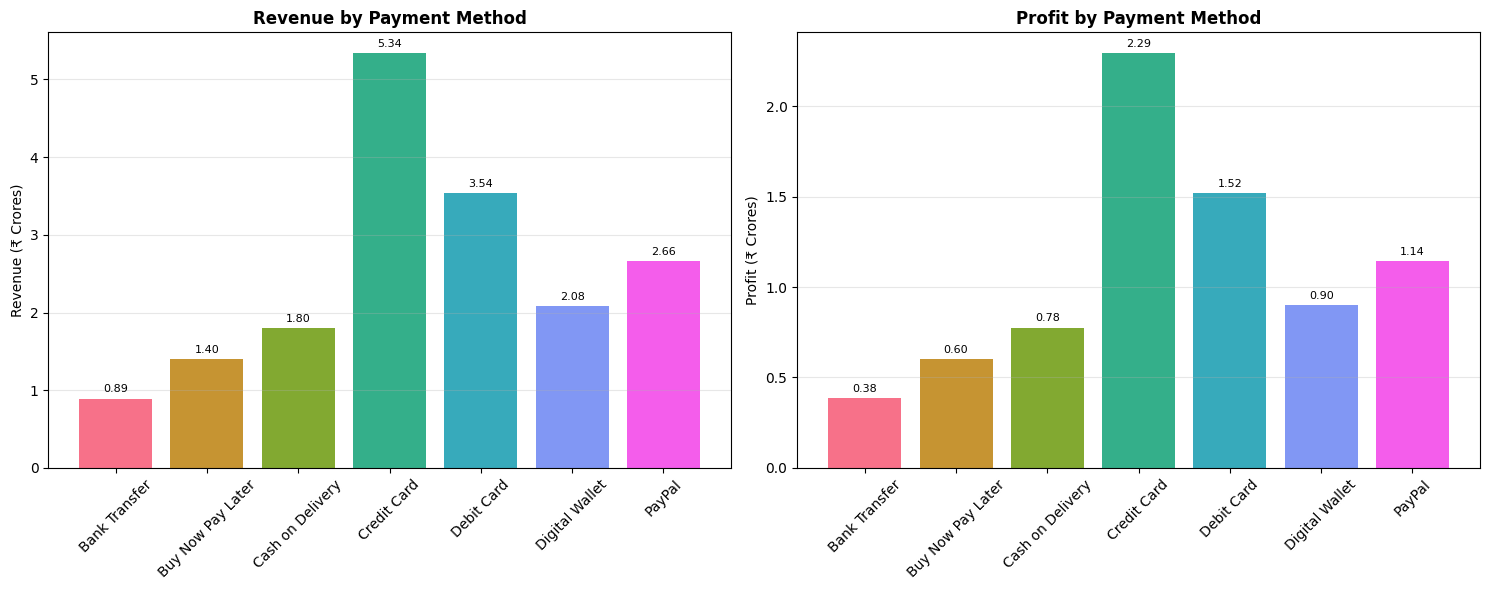

In [ ]:
payment_analysis = df.groupby('payment_method').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Revenue=('net_sales', 'sum'),
    Total_Profit=('profit', 'sum')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = sns.color_palette("husl", len(payment_analysis))

# Revenue Chart
bars1 = axes[0].bar(
    payment_analysis['payment_method'],
    payment_analysis['Total_Revenue'] / 10000000,
    color=colors
)
axes[0].set_title('Revenue by Payment Method', fontweight='bold')
axes[0].set_ylabel('Revenue (₹ Crores)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].bar_label(bars1, fmt='%.2f', padding=3, fontsize=8)

# Profit Chart
bars2 = axes[1].bar(
    payment_analysis['payment_method'],
    payment_analysis['Total_Profit'] / 10000000,
    color=colors
)
axes[1].set_title('Profit by Payment Method', fontweight='bold')
axes[1].set_ylabel('Profit (₹ Crores)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].bar_label(bars2, fmt='%.2f', padding=3, fontsize=8)

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

1. Credit Card generates the highest revenue of ₹5.34 Crores.

2. Credit Card contributes the highest profit of ₹2.29 Crores.

3. Debit Card ranks second in revenue with ₹3.54 Crores.

4. PayPal generates ₹2.66 Crores in revenue.

5. Digital Wallet contributes ₹2.08 Crores in revenue.

6. Cash on Delivery generates ₹1.80 Crores in revenue.

7. Buy Now Pay Later generates ₹1.40 Crores in revenue.

8. Bank Transfer records the lowest revenue of ₹89.24 Lakhs.

9. Credit Card has the highest order count with 41,460 orders.

10. Digital payment methods contribute significantly to overall sales.

# 34. Year-wise Profit Trend Analysis

This analysis examines yearly profit performance to identify changes in profitability from 2021 to 2025.

In [ ]:
yearly_profit = df.groupby('order_year').agg(
    Total_Profit=('profit', 'sum'),
    Total_Revenue=('net_sales', 'sum')
).reset_index()

display(yearly_profit)

,order_year,Total_Profit,Total_Revenue
0,2021,15325651.87,35722650.67
1,2022,15167978.69,35327882.62
2,2023,15247695.95,35528143.74
3,2024,15292965.09,35466452.28
4,2025,15112104.16,35089134.43


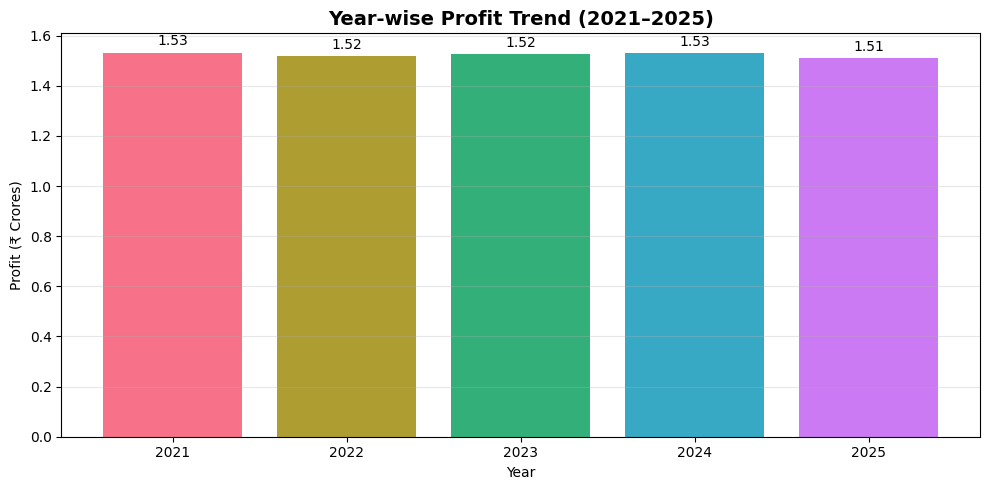

In [ ]:
plt.figure(figsize=(10, 5))

colors = sns.color_palette("husl", 5)

bars = plt.bar(
    yearly_profit['order_year'].astype(str),
    yearly_profit['Total_Profit'] / 10000000,
    color=colors
)

plt.title('Year-wise Profit Trend (2021–2025)',
          fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Profit (₹ Crores)')
plt.bar_label(bars, fmt='%.2f', padding=3)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Key Insights

1. The highest yearly profit was recorded in 2021 at ₹1.53 Crores.

2. The lowest yearly profit was recorded in 2025 at ₹1.51 Crores.

3. Profit remained relatively stable between 2021 and 2025.

4. The year 2024 generated ₹1.53 Crores in profit.

5. The business maintained consistent profitability across all five years.

# 35. Overall Key Insights

1. The dataset contains 138,116 records and 49 columns after feature engineering and data cleaning.

2. Total revenue generated is ₹17.71 Crores.

3. Total profit generated is ₹7.61 Crores.

4. Average sales value is ₹1,282.50.

5. The Mobile App is the leading sales channel, generating approximately ₹7.08 Crores in revenue.

6. The South region generates the highest revenue of ₹5.56 Crores.

7. Electronics is the top-performing product category, generating ₹4.11 Crores in revenue.

8. Samsung is the leading brand in revenue, contributing ₹69.22 Lakhs.

9. Amazon Supply generates the highest supplier-wise revenue of ₹2.32 Crores.

10. Positive customer reviews contribute the highest revenue of approximately ₹10.14 Crores.

11. The 0–10% discount range generates the highest revenue and profit.

12. Credit Card is the leading payment method, generating approximately ₹5.34 Crores in revenue.

13. The Completed order status accounts for 113,559 orders.

14. The year-wise analysis shows relatively stable revenue and profit performance from 2021 to 2025.

15. Discounts above 50% result in a negative total profit of approximately ₹2.05 Lakhs.

# 36. Final Project Conclusion

This E-Commerce Sales and Customer Behavior Analysis project was completed using Python.

The project involved data loading, data cleaning, feature engineering, statistical analysis, exploratory data analysis, and data visualization.

Pandas and NumPy were used for data manipulation and analysis. Matplotlib and Seaborn were used to create colourful visualizations.

The analysis helped identify sales trends, customer purchasing behaviour, product performance, brand performance, supplier performance, payment preferences, and discount impact.

Overall, this project demonstrates how Python-based data analytics can transform raw e-commerce data into meaningful business insights and support data-driven decision-making.

## BUSINESS RECOMMENDATIONS

1. **Improve Mobile App Sales:** The Mobile App generated the highest revenue of approximately ₹7.08 Crores. The business should focus on improving app features and customer experience to maintain sales growth.

2. **Focus on High-Performing Products:** Electronics generated the highest product category revenue of approximately ₹4.11 Crores. The business should maintain product availability and monitor demand.

3. **Strengthen Regional Performance:** The South region recorded the highest revenue of approximately ₹5.56 Crores. Successful sales strategies from this region can be evaluated for other regions.

4. **Improve Marketing Strategies:** Organic Search generated the highest marketing channel revenue of approximately ₹3.57 Crores. The business should continue improving SEO and website visibility.

5. **Control Excessive Discounts:** Discounts above 50% resulted in negative profit. The business should review high-discount offers and maintain profitable discount levels.

6. **Improve Delivery Performance:** Although most orders were delivered on time, delayed deliveries should be monitored to improve customer satisfaction.

7. **Monitor Customer Feedback:** Positive reviews contributed the highest revenue. The business should continue monitoring customer ratings and addressing negative feedback.

8. **Encourage Digital Payments:** Credit Card payments generated the highest revenue among payment methods. The business can improve the convenience and security of digital payment options.

9. **Maintain Customer Loyalty:** Loyal customers contributed the majority of orders. The business should focus on customer retention and loyalty programs.

10. **Monitor Year-wise Performance:** Revenue and profit remained relatively stable from 2021 to 2025. Regular performance monitoring can help identify opportunities for improvement.

## PROJECT LIMITATIONS

1. **Dataset Dependency:** The analysis was performed using the available e-commerce dataset. The results depend on the accuracy and completeness of the dataset.

2. **Limited Data Scope:** The project covers data from 2021 to 2025 and may not represent all e-commerce businesses or markets.

3. **Missing Values:** Some missing values were identified and handled during data cleaning. This process may have influenced certain analysis results.

4. **Historical Data Analysis:** The project focuses on historical data and does not include future sales forecasting.

5. **External Factors:** Competitor activities, economic conditions, seasonal market changes, and other external factors were not considered.

6. **Customer Behavior:** Customer purchasing behavior was analyzed using the available dataset. Additional customer surveys could provide deeper insights.

7. **Profit Calculation:** Profit analysis is based on the profit values provided in the dataset and may not include all real-world business expenses.